> **Copia para repositorio, sin reejecutar el EDA.** Solo se conservan salidas agregadas de las ejecuciones locales anteriores, fechadas en `docs/eda/README.md`. Se retiraron las demás salidas: microfotografías, captions completos, muestras y rutas personales. Se conserva el código de análisis. Configuración y protección de archivos adaptadas; reglas sin cambios. Los respaldos del historial permanecen locales. Una ejecución futura vuelve a producir resultados privados que no deben publicarse automáticamente.

# EDA de LeukemiaAttri

**Alcance:** únicamente los cinco fragmentos de `Dataset/LeukemiaAttri`. No se agregan otras carpetas ni ZIP de respaldo. Los ZIP internos de etiquetas se leen en memoria, sin extraerlos. Se conservan imágenes, captions y particiones. No se ejecutan notebooks antiguos, entrenan modelos, generan captions o producen recortes para entrenamiento.

Este documento diferencia **archivos de imagen**, **referencias JSON**, **registros de anotación celular**, **líneas TXT** y **filas de captions**. El conteo de registros no prueba cuántas células biológicamente distintas existen. JSON y TXT se analizan como representaciones de anotaciones, nunca se suman como células independientes.

La procedencia del CSV de Arturo fue confirmada por el usuario; no es verificación independiente de autoría/contenido. El [README del repositorio de referencia](https://github.com/AndresGDS/TrabajoTerminal-Prediagnostico-leucemia) señala H_100X_C2 para su flujo. Aquí esa selección motiva un resumen específico; no valida los diccionarios ni la calidad diferencial de ese subconjunto. Las afirmaciones de procedencia experta del repositorio no se comprueban con los archivos locales.

## Ejecución y reproducibilidad

Python 3 y `pandas numpy matplotlib Pillow nbformat nbclient ipykernel`. Instalar en el entorno elegido con `python -m pip install pandas numpy matplotlib Pillow nbformat nbclient ipykernel`. Configurar rutas abajo y ejecutar todas las celdas en orden (Restart Kernel and Run All Cells). El notebook es el documento principal; una base SQLite conserva tablas completas, tres PNG las distribuciones y un PDF los ejemplos con cajas. Las tablas visibles grandes muestran ejemplos y lo indican expresamente. Reejecutar reemplaza únicamente derivados en `resultados_leukemiaattri`.

Las pruebas del lector comprueban su funcionamiento y límites, **no la exactitud morfológica de las anotaciones**.

**Actualización del 2026-10-11:** la sección 12 amplía cobertura, comparabilidad de duplicados y geometría usando las tablas de origen; no representa una inspección nueva. Las salidas de las secciones 1–11 se conservan. Véanse los requisitos de ejecución parcial al inicio de la sección 12.

In [1]:
from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict
from contextlib import closing
from datetime import datetime, timezone
import sys, json, re, hashlib, sqlite3, zipfile, io, warnings, gc, math
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.backends.backend_pdf import PdfPages
from PIL import Image
from IPython.display import display, Markdown, HTML
from html import escape

# RUTAS CONFIGURABLES: no se necesitan modificaciones en los originales.
# Configurar HEMVLM_EDA_*; ver docs/eda/README.md.
HERE=Path.cwd().resolve()
REPO_ROOT=next((p for p in [HERE,*HERE.parents] if (p/'notebooks/eda/eda_paths.py').is_file()),None)
assert REPO_ROOT is not None, 'Iniciar desde el repositorio o notebooks/eda'
sys.path.insert(0,str(REPO_ROOT/'notebooks/eda'))
from eda_paths import eda_paths
EDA_PATHS=eda_paths()
DATASET_DIR=EDA_PATHS['dataset']
ROOT=EDA_PATHS['leukemiaattri']
CAPTIONS_CSV=EDA_PATHS['captions']
OUTPUT_DIR=EDA_PATHS['output']/'resultados_leukemiaattri'
FRAGMENT_NAMES=[f'LeukemiaAttri_Dataset-20260907T175427Z-1-{i:03d}' for i in range(1,6)]
FOCUS='H_100X_C2';SEED=20261009
for name in FRAGMENT_NAMES:assert (ROOT/name).is_dir(),name
assert CAPTIONS_CSV.is_file()
assert OUTPUT_DIR.resolve()!=ROOT.resolve()
OUTPUT_DIR.mkdir(parents=True,exist_ok=True);DB=OUTPUT_DIR/'tablas_eda.sqlite'
def sha_bytes(raw):return hashlib.sha256(raw).hexdigest()
def sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for part in iter(lambda:f.read(1048576),b''):h.update(part)
    return h.hexdigest()
def literal(x):return json.dumps(x,ensure_ascii=False,sort_keys=True,separators=(',',':'))
def save(name,df):
    with closing(sqlite3.connect(DB)) as con:df.to_sql(name,con,if_exists='replace',index=False)
def say(s):display(Markdown(s))
def show(df,n=15):
    display(df.head(n))
    if len(df)>n:print(f'Muestra visible: {n} de {len(df)} filas; tabla completa en SQLite.')
plt.rcParams.update({'figure.dpi':100});pd.set_option('display.max_colwidth',100)
protected_paths=[REPO_ROOT/'notebooks/eda/01_EDA_WBCAtt.ipynb',REPO_ROOT/'docs/eda/INVENTARIO_INICIAL.md',*sorted((EDA_PATHS['output']/'resultados_wbcatt').rglob('*'))]
protected_before={str(p):sha(p) for p in protected_paths if p.is_file()}
source_hashes={str(CAPTIONS_CSV):sha(CAPTIONS_CSV)}
run_utc=datetime.now(timezone.utc).isoformat()
display(pd.Series({'Python':sys.version,**{p:metadata.version(p) for p in ['pandas','numpy','matplotlib','Pillow','nbformat','nbclient','ipykernel']}},name='versión').to_frame())
print('Ejecución UTC:',run_utc);print('Fuente:',ROOT);print('Resultados:',OUTPUT_DIR)
issues=[]
def issue(kind,source,record,detail):issues.append({'tipo':kind,'fuente':source,'registro':str(record),'detalle':str(detail)})


,versión
Python,"3.14.6 | packaged by Anaconda, Inc. | (main, Jul 9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]"
pandas,3.0.3
numpy,2.4.6
matplotlib,3.11.0
Pillow,12.3.0
nbformat,5.10.4
nbclient,0.11.0
ipykernel,6.31.0


## 1. Inventario de imágenes y estructura

**Pregunta:** ¿qué archivos hay en los cinco fragmentos y cómo se distribuyen? **Método:** recorrido completo limitado a esas carpetas. Se conserva la ruta física y se deriva una clave lógica `(subconjunto, partición, ruta relativa dentro de Images)`. Solo los componentes estructurales `Images/images` y `Train/train/Test/test` se interpretan sin distinguir mayúsculas; los nombres de archivo se conservan exactamente. No se unen nombres aislados.

Los tokens H/L, C1/C2 y 10X/40X/100X proceden de nombres de carpeta; se conservan como códigos de configuración, cámara y aumento declarado por ruta. No se asignan modelos de cámara ni identidad de paciente. Las carpetas sin archivos se registran también. **Resultado e interpretación:** las tablas siguientes cuentan archivos físicos, no referencias o células.

In [ ]:
files=[];folders=[]
for name in FRAGMENT_NAMES:
    base=ROOT/name
    files.extend(p for p in base.rglob('*') if p.is_file())
    folders.extend(p for p in (base/'LeukemiaAttri_Dataset').iterdir() if p.is_dir())
files=sorted(files)
SUBRE=re.compile(r'^(H|L)_(\d+X)_(C\d+)$')
all_subsets=sorted({p.name for p in folders})
image_rows=[];physical=[]
for p in files:
    parts=p.relative_to(ROOT).parts;physical.append({'ruta':p.relative_to(ROOT).as_posix(),'fragmento':parts[0],'extension':p.suffix.lower(),'bytes':p.stat().st_size})
    if p.suffix.lower() not in {'.png','.jpg','.jpeg','.tif','.tiff','.bmp'}:continue
    subset=parts[2];m=SUBRE.fullmatch(subset)
    if len(parts)<6 or parts[3].casefold()!='images' or parts[4].casefold() not in {'train','test','val'}:
        issue('ruta_imagen_no_reconocida',p.relative_to(ROOT).as_posix(),'',parts);continue
    split=parts[4].casefold();relative='/'.join(parts[5:]);key=literal([subset,split,relative])
    image_rows.append({'image_uid':len(image_rows),'physical_rel':p.relative_to(ROOT).as_posix(),'fragmento':parts[0],'subset':subset,'config_code':m.group(1) if m else '', 'camera_code':m.group(3) if m else '', 'magnification_path':m.group(2) if m else '', 'split':split,'split_original':parts[4],'relative_image':relative,'image_key':key,'filename':p.name})
images=pd.DataFrame(image_rows);inventory=pd.DataFrame(physical)
folder_inventory=pd.DataFrame([{'ruta':p.relative_to(ROOT).as_posix(),'subset':p.name,'archivos_recursivos':sum(1 for q in p.rglob('*') if q.is_file())} for p in folders])
img_distribution=images.groupby(['subset','config_code','camera_code','magnification_path','split']).size().reset_index(name='archivos_imagen')
show(inventory.groupby(['fragmento','extension']).size().reset_index(name='archivos'),30);display(img_distribution);show(folder_inventory[folder_inventory.archivos_recursivos.eq(0)])
key_index=images.groupby('image_key').image_uid.agg(list).to_dict();image_by_uid=images.set_index('image_uid').to_dict('index')
save('archivos_fisicos',inventory);save('carpetas_subconjuntos',folder_inventory);save('imagenes_inventario',images);save('imagenes_distribucion',img_distribution)
say(f'**{len(images):,} archivos de imagen**, **{images.subset.nunique()} subconjuntos con imágenes**, **{len(all_subsets)} nombres de subconjunto en carpetas**. Hay **{sum(len(v)>1 for v in key_index.values())} claves lógicas con varios archivos físicos**: se conservarán como asociaciones ambiguas, incluso si después sus bytes coinciden.')


## 2. Fuentes de anotación y copias

**Pregunta:** ¿qué JSON/TXT son copias y qué procedencia tienen? **Método:** listar JSON sueltos y miembros JSON/TXT de los ZIP internos sin extraerlos. Se conserva ruta, miembro y posición dentro del ZIP, hash de bytes y hash de contenido estructurado. JSON se compara con claves ordenadas, conservando tipos y orden de listas. TXT se compara por secuencia de líneas tokenizadas; solo se ignoran diferencias de espacios y líneas vacías para detectar copias, preservando bytes/líneas originales.

Una copia solo se agrupa dentro del mismo subconjunto/partición; en TXT también se exige la misma ruta de imagen esperada. Se conserva toda procedencia y se elige un representante determinista para **no duplicar el conteo documental**. Si dos variantes difieren, ambas permanecen. Esto no elimina datos ni demuestra equivalencia entre JSON y TXT o entre sus clases.

In [ ]:
docs=[];payloads={};zip_inventory=[]
def context_from_path(p,member=''):
    parts=p.relative_to(ROOT).parts;subset=parts[2]
    effective=member if member else p.name
    names=PurePosixPath(effective.replace('\\','/')).parts
    split=next((x.casefold() for x in reversed(names[:-1]) if x.casefold() in {'train','test','val'}),'')
    if p.suffix.lower()=='.json' or effective.lower().endswith('.json'):
        stem=PurePosixPath(effective).stem.casefold()
        if stem in {'train','test','val'}:split=stem
    return subset,split

def add_doc(p,raw,member='',member_index=-1):
    ext=PurePosixPath(member).suffix.lower() if member else p.suffix.lower()
    subset,split=context_from_path(p,member);sid=f'S{len(docs):06d}';loc=p.relative_to(ROOT).as_posix()+('!'+member if member else '')
    row={'source_id':sid,'source':loc,'physical_file':p.relative_to(ROOT).as_posix(),'zip_member':member,'zip_index':member_index,'subset':subset,'split':split,'format':ext[1:],'sha256_bytes':sha_bytes(raw),'semantic_sha256':'','decode_error':'','family_path':str(PurePosixPath(member).parent) if member else 'json_suelto','expected_image':''}
    try:
        text=raw.decode('utf-8-sig')
        if ext=='.json':data=json.loads(text);canonical=literal(data)
        else:
            data=text.splitlines();canonical=literal([x.split() for x in data if x.split()]);label_parts=PurePosixPath(member if member else p.name).parts; pos=next((i for i,x in enumerate(label_parts) if x.casefold() in {'train','test','val'}),-1); label_rel=PurePosixPath(*label_parts[pos+1:]) if pos>=0 else PurePosixPath(label_parts[-1]); row['expected_image']=label_rel.with_suffix('.png').as_posix()
        row['semantic_sha256']=sha_bytes(canonical.encode('utf-8'));payloads[sid]=data
    except Exception as e:row['decode_error']=f'{type(e).__name__}: {e}';issue('anotacion_no_legible',loc,'',row['decode_error'])
    docs.append(row)
for p in files:
    if p.suffix.lower()=='.json':source_hashes[str(p)]=sha(p);add_doc(p,p.read_bytes())
    elif p.suffix.lower()=='.zip':
        source_hashes[str(p)]=sha(p)
        with zipfile.ZipFile(p) as z:
            for idx,item in enumerate(z.infolist()):
                if item.is_dir():continue
                ext=PurePosixPath(item.filename).suffix.lower();zip_inventory.append({'zip':p.relative_to(ROOT).as_posix(),'member_index':idx,'member':item.filename,'extension':ext,'bytes':item.file_size})
                if ext in {'.json','.txt'}:add_doc(p,z.read(item),item.filename,idx)
sources=pd.DataFrame(docs);representatives={};canonical_ids=[]
for row in sources.to_dict('records'):
    key=(row['subset'],row['split'],row['format'],row['expected_image'],row['semantic_sha256'])
    if row['decode_error']:canonical_ids.append(row['source_id']);continue
    representatives.setdefault(key,row['source_id']);canonical_ids.append(representatives[key])
sources['canonical_source']=canonical_ids;sources['is_canonical']=sources.source_id.eq(sources.canonical_source)
source_lookup=sources.set_index('source_id').to_dict('index')
doc_counts=sources.groupby(['subset','split','format']).agg(ubicaciones=('source_id','size'),documentos_sin_copias=('is_canonical','sum')).reset_index()
display(doc_counts);show(sources.loc[~sources.is_canonical,['source_id','source','canonical_source','format']],12)
save('anotaciones_fuentes',sources);save('zip_miembros',pd.DataFrame(zip_inventory));save('anotaciones_conteos_documentales',doc_counts)
say(f'Hay **{len(sources):,} ubicaciones de anotación**, **{int(sources.is_canonical.sum()):,} representantes documentales** y **{int((~sources.is_canonical).sum()):,} ubicaciones de copias**. Se conserva la relación con cada fuente. Los TXT vacíos iguales siguen siendo archivos sin anotaciones, no células.')


## 3. Lectura de esquemas y valores literales

**Pregunta:** ¿qué representan los registros y qué puede interpretarse con seguridad? **Método:** leer representantes documentales sin modificar fuentes. JSON usa listas `images`, `annotations`, `categories`, con referencias locales al documento. Se preserva cada registro JSON completo. En TXT se conserva número de línea, texto, tokens y cantidad de columnas: cinco = clase y cuatro coordenadas candidatas de detección; doce = esos cinco más siete tokens de atributo **por posición**, sin atribuirles nombres o significado. Cualquier otra longitud se conserva como formato no interpretado.

Las coordenadas se evalúan numéricamente solo si tienen sintaxis decimal finita inequívoca. Tokens de clase/atributo permanecen literales: `l` no se convierte en `1`, y códigos como `2` o `none` no se convierten en ausencia por suposición. Un nombre de carpeta AttriDet no garantiza doce columnas. No se presupone que el código TXT y `category_id` JSON compartan diccionario.

**Resultado e interpretación:** las tablas presentan registros por formato y muestras originales, no una suma de células JSON+TXT. Las pruebas sintéticas verifican funcionamiento del lector, no corrección de anotaciones.

In [ ]:
NUM=re.compile(r'^[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?$')
def number(token):
    if isinstance(token,bool):return None
    if not isinstance(token,(int,float,str)):return None
    s=str(token)
    if not NUM.fullmatch(s):return None
    x=float(s)
    return x if math.isfinite(x) else None
assert number('l') is None and number('1')==1 and number('1e-3')==.001 and number('nan') is None
ATTRS=['cell_size','nuclear_chromatio','nuclear_shape','nucleolus','cytoplasm','cytoplasmic_basophilia','cytoplasmic_vacuoles']
refs=[];anns=[];categories=[];txt=[];doc_stats=[]
for d in sources.loc[sources.is_canonical].to_dict('records'):
    sid=d['source_id'];data=payloads.get(sid)
    if data is None:continue
    base={'source_id':sid,'subset':d['subset'],'split':d['split']}
    if d['format']=='json':
        if not isinstance(data,dict):issue('JSON_raiz_no_objeto',d['source'],'',type(data).__name__);continue
        for idx,r in enumerate(data.get('images',[])):
            if not isinstance(r,dict):issue('JSON_referencia_no_objeto',d['source'],idx,literal(r));continue
            refs.append({**base,'ref_uid':len(refs),'record_index':idx,'id_literal':literal(r.get('id')),'file_name':str(r.get('file_name','')),'width_declared':number(r.get('width')),'height_declared':number(r.get('height')),'raw_json':literal(r)})
        for idx,r in enumerate(data.get('annotations',[])):
            if not isinstance(r,dict):issue('JSON_anotacion_no_objeto',d['source'],idx,literal(r));continue
            row={**base,'ann_uid':len(anns),'record_index':idx,'id_literal':literal(r.get('id')),'image_id_literal':literal(r.get('image_id')),'category_id_literal':literal(r.get('category_id')),'category_name_literal':literal(r.get('category_name')),'cell_id_literal':literal(r.get('cell_id')),'bbox_literal':literal(r.get('bbox')),'raw_json':literal(r),'raw_sha256':sha_bytes(literal(r).encode())}
            for a in ATTRS:row[a]=literal(r[a]) if a in r else '__CAMPO_AUSENTE__'
            anns.append(row)
        for idx,r in enumerate(data.get('categories',[])):categories.append({**base,'record_index':idx,'id_literal':literal(r.get('id')),'name_literal':literal(r.get('name')),'raw_json':literal(r)})
        doc_stats.append({**base,'format':'json','n_refs':len(data.get('images',[])),'n_annotations':len(data.get('annotations',[])),'n_lines':0,'n_blank':0})
    else:
        blanks=0
        for line_no,line in enumerate(data,1):
            tokens=line.split()
            if not tokens:blanks+=1;continue
            ncols=len(tokens);row={**base,'txt_uid':len(txt),'line_no':line_no,'original_line':line,'tokens_json':literal(tokens),'n_columns':ncols,'schema':('deteccion_5' if ncols==5 else 'atributos_12' if ncols==12 else 'otro'),'class_token':tokens[0],'expected_image':d['expected_image'],'record_sha256':sha_bytes(literal(tokens).encode())}
            for i in range(7):row[f'attr_p{i+1}']=tokens[i+5] if ncols==12 else None
            txt.append(row)
            if ncols not in {5,12}:issue('TXT_numero_columnas_no_interpretado',d['source'],line_no,ncols)
            for pos,token in enumerate(tokens):
                if number(token) is None:issue('TXT_token_no_numerico_conservado',d['source'],line_no,f'posición {pos+1}: {token!r}; no convertido')
        doc_stats.append({**base,'format':'txt','n_refs':0,'n_annotations':0,'n_lines':len(data)-blanks,'n_blank':blanks})
refs=pd.DataFrame(refs);anns=pd.DataFrame(anns);cats=pd.DataFrame(categories);txt=pd.DataFrame(txt);doc_stats=pd.DataFrame(doc_stats)
save('json_referencias_originales',refs);save('json_anotaciones_originales',anns);save('json_categorias',cats);save('txt_registros_originales',txt);save('documentos_estadisticas',doc_stats)
lengths=txt.groupby(['subset','split','schema','n_columns']).size().reset_index(name='lineas_representantes');save('txt_esquemas',lengths)
display(txt.groupby(['schema','n_columns']).size().reset_index(name='lineas'))
for schema,g in txt.groupby('schema'):
    say(f'**Ejemplo literal: {schema}**');show(g[['source_id','line_no','original_line']],2)
say('**Muestra JSON (se conserva el registro entero):**');print(refs.iloc[0].raw_json);print(anns.iloc[0].raw_json)
say(f'Los representantes contienen **{len(refs):,} referencias JSON**, **{len(anns):,} registros de anotación JSON** y **{len(txt):,} líneas TXT no vacías**. Son unidades diferentes y no se suman. Los siete atributos JSON conservan nombre y valor original; los siete TXT se identifican solo por posición.')


## 4. Imágenes: decodificación completa y hashes

**Pregunta:** ¿qué archivos se pueden leer y qué tamaños/canales tienen? **Método:** nueva lectura secuencial de todos los archivos principales. Se decodifica con Pillow, se registran excepciones y advertencias por separado y se calculan hashes SHA-256 de bytes y de píxeles RGBA con dimensiones incluidas. RGBA agrega alfa opaco a RGB; no se redimensiona, corrige color ni aplica orientación EXIF. Es una representación temporal de comparación, no modificación de archivos.

Las conexiones SQLite se cierran explícitamente y las advertencias se capturan sin hilos compartidos. **Resultado e interpretación:** lectura exitosa no implica calidad clínica ni etiquetas correctas. Los errores y mensajes completos permanecen trazables en SQLite.

**Registro de ejecución:** un intento anterior alcanzó el límite de tiempo antes de completar la inspección. Se vuelve a ejecutar desde las fuentes. Se guarda progreso cada 500 archivos en `imagenes_inspeccion_checkpoint`, dentro de la misma SQLite; esa tabla es técnica y no agrega imágenes a los conteos. Las conclusiones usan solo la inspección completa. No se presenta el intento interrumpido como verificación concluida.

In [ ]:
def inspect_image(row):
    result={'image_uid':row['image_uid'],'error':'','warning':'','warning_details':'[]'};captured=[]
    try:
        raw=(ROOT/row['physical_rel']).read_bytes();result['file_sha256']=sha_bytes(raw);result['bytes_read']=len(raw)
        with warnings.catch_warnings(record=True) as captured:
            warnings.simplefilter('always')
            with Image.open(io.BytesIO(raw)) as im:
                im.load();result.update(width=im.width,height=im.height,mode=im.mode,channels=len(im.getbands()),format=im.format)
                pixels=np.asarray(im.convert('RGBA'),dtype=np.uint8);h=hashlib.sha256();h.update(f'RGBA|uint8|{im.width}|{im.height}|'.encode());h.update(pixels.tobytes());result['pixel_sha256']=h.hexdigest()
    except Exception as e:result['error']=f'{type(e).__name__}: {e}'
    finally:
        result['warning']=' | '.join(str(x.message) for x in captured)
        result['warning_details']=literal([{'category':x.category.__name__,'message':str(x.message),'module':x.filename,'line':x.lineno} for x in captured])
    return result
gc.collect();inspection=[];last_checkpoint=0
for i,row in enumerate(images.to_dict('records'),1):
    inspection.append(inspect_image(row))
    if i%500==0 or i==len(images):
        batch=pd.DataFrame(inspection[last_checkpoint:]);batch['run_utc']=run_utc
        with closing(sqlite3.connect(DB)) as con:batch.to_sql('imagenes_inspeccion_checkpoint',con,if_exists='replace' if last_checkpoint==0 else 'append',index=False)
        last_checkpoint=i
        print(f'Inspeccionados {i:,}/{len(images):,}; avance guardado',flush=True)
info=images.merge(pd.DataFrame(inspection),on='image_uid',validate='one_to_one')
for col in ['width','height','mode','channels','file_sha256','pixel_sha256']:
    if col not in info:info[col]=None
info_by_uid=info.set_index('image_uid').to_dict('index')
formats=info.groupby(['subset','split','width','height','mode','channels'],dropna=False).size().reset_index(name='archivos')
save('imagenes_inspeccion',info);save('imagenes_formatos',formats);show(formats,30)
for row in info.loc[info.error.ne('')|info.warning.ne('')].to_dict('records'):
    print('Ruta:',ROOT/row['physical_rel'],'\nError:',row['error'],'\nAdvertencia:',row['warning'],'\nDetalle:',row['warning_details'])
    issue('imagen_error_o_advertencia',row['physical_rel'],row['image_uid'],literal({'error':row['error'],'warning':row['warning']}))
say(f'Se leyeron **{len(info):,} archivos**: **{int(info.error.ne("").sum())} errores** y **{int(info.warning.ne("").sum())} archivos con advertencias**. Cada dimensión/canal corresponde a una lectura, no a una muestra. No se excluyeron archivos.')


## 5. Correspondencias, geometría y cobertura

**Pregunta:** ¿cada referencia y anotación conduce a un archivo y contiene cajas/atributos utilizables? **Método:** clave de subconjunto+partición+ruta, con identificadores JSON locales a su documento. Una referencia repetida a la misma imagen se conserva como referencia adicional, no imagen nueva. Identificadores de imagen duplicados dentro de un JSON se marcan como ambiguos. Se contrastan dimensiones declaradas y reales.

Para JSON se verifica el esquema geométrico COCO `[x,y,ancho,alto]`: cuatro números finitos, tamaño positivo y límites de imagen. Para TXT de cinco/doce columnas se diagnostican las cuatro posiciones como **hipótesis convencional** `[centro_x,centro_y,ancho,alto]` normalizada. Las incidencias TXT son condicionales a esa convención, no una validación documental del formato. No se convierten códigos de clase/atributo.

Cajas o registros iguales pueden ser repeticiones de anotación, no nuevas células. Se conserva todo: se muestran conteos brutos y firmas coincidentes, sin aplicar exclusiones. JSON y TXT no se suman ni se presume una correspondencia celular uno a uno.

**Aclaración posterior:** la sección 12.1 desglosa ausencia de referencia, ausencia de registros y existencia de documentos TXT; amplía esta cobertura sin modificarla.

In [ ]:
def relative_ref(filename,subset,split):
    value=str(filename).replace('\\','/')
    pp=PurePosixPath(value)
    if pp.is_absolute() or '..' in pp.parts:return '', 'ruta_no_relativa'
    parts=list(pp.parts)
    if parts and parts[0]==subset:parts=parts[1:]
    if parts and parts[0].casefold()=='images':parts=parts[1:]
    if parts and parts[0].casefold() in {'train','test','val'}:
        if parts[0].casefold()!=split:return '', 'particion_en_ruta_discrepante'
        parts=parts[1:]
    return '/'.join(parts), '' if parts else 'ruta_vacia'
def associate(subset,split,filename):
    rel,err=relative_ref(filename,subset,split)
    if err:return {'association':err,'image_uid':None,'image_key':'','candidates_json':'[]'}
    key=literal([subset,split,rel]);candidates=key_index.get(key,[])
    return {'association':'unica' if len(candidates)==1 else 'ambigua' if len(candidates)>1 else 'faltante','image_uid':candidates[0] if len(candidates)==1 else None,'image_key':key,'candidates_json':literal(candidates)}
assert relative_ref('Images/Train/a.png','H_100X_C2','train')==('a.png','')
assert relative_ref('../a.png','H_100X_C2','train')[1]=='ruta_no_relativa'
refs=pd.concat([refs,pd.DataFrame([associate(r.subset,r.split,r.file_name) for r in refs.itertuples()])],axis=1)
ref_ids=defaultdict(list)
for r in refs.to_dict('records'):ref_ids[(r['source_id'],r['id_literal'])].append(r)
annlinks=[]
for r in anns.to_dict('records'):
    rr=ref_ids.get((r['source_id'],r['image_id_literal']),[])
    if len(rr)==1:link={k:rr[0][k] for k in ['association','image_uid','image_key','candidates_json']};link['ref_uid']=rr[0]['ref_uid']
    else:link={'association':'id_imagen_ausente' if not rr else 'id_imagen_ambiguo','image_uid':None,'image_key':'','candidates_json':'[]','ref_uid':None}
    annlinks.append(link)
anns=pd.concat([anns,pd.DataFrame(annlinks)],axis=1)
txt=pd.concat([txt,pd.DataFrame([associate(r.subset,r.split,r.expected_image) for r in txt.itertuples()])],axis=1)
for frame,kind,idx in [(refs,'JSON_referencia','record_index'),(anns,'JSON_anotacion','record_index'),(txt,'TXT_linea','line_no')]:
    for r in frame.loc[frame.association.ne('unica')].to_dict('records'):issue(kind+'_asociacion_'+r['association'],source_lookup[r['source_id']]['source'],r[idx],r['candidates_json'])
for r in refs.loc[refs.association.eq('unica')].to_dict('records'):
    actual=info_by_uid[int(r['image_uid'])]
    if r['width_declared']!=actual.get('width') or r['height_declared']!=actual.get('height'):issue('JSON_dimensiones_discrepantes',source_lookup[r['source_id']]['source'],r['record_index'],literal({'declaradas':[r['width_declared'],r['height_declared']],'reales':[actual.get('width'),actual.get('height')],'ruta':actual['physical_rel']}))

def validate_box(values,width=None,height=None,normalized=False):
    if not isinstance(values,(list,tuple)) or len(values)!=4:return 'formato_no_4'
    v=[number(x) for x in values]
    if any(x is None for x in v):return 'coordenada_no_numerica_finita'
    x,y,bw,bh=v
    if bw<=0 or bh<=0:return 'tamano_no_positivo'
    if normalized:x,y=x-bw/2,y-bh/2;width=height=1
    if x<0 or y<0:return 'origen_fuera_limites'
    if width is None or height is None or pd.isna(width) or pd.isna(height):return 'limites_no_verificables'
    if x+bw>width+1e-9 or y+bh>height+1e-9:return 'extension_fuera_limites'
    return 'valida_geometricamente'
assert validate_box([0,0,10,10],10,10)=='valida_geometricamente'
assert validate_box([0,0,-1,10],10,10)=='tamano_no_positivo'
assert validate_box(['l',0,1,1],10,10)=='coordenada_no_numerica_finita'
ann_quality=[]
cat_index=defaultdict(list)
for row in cats.to_dict('records'):cat_index[(row['source_id'],row['id_literal'])].append(row['name_literal'])
for row in anns.to_dict('records'):
    im=info_by_uid.get(int(row['image_uid'])) if pd.notna(row['image_uid']) else None
    box=json.loads(row['bbox_literal']);status=validate_box(box,im.get('width') if im else None,im.get('height') if im else None)
    names=cat_index.get((row['source_id'],row['category_id_literal']),[])
    catstatus='ausente' if not names else 'ambigua' if len(names)!=1 else 'coincide' if names[0]==row['category_name_literal'] else 'nombre_discrepante'
    ann_quality.append({'bbox_status':status,'category_status':catstatus})
    if status!='valida_geometricamente':issue('JSON_caja_'+status,source_lookup[row['source_id']]['source'],row['record_index'],row['bbox_literal'])
    if catstatus!='coincide':issue('JSON_categoria_'+catstatus,source_lookup[row['source_id']]['source'],row['record_index'],literal([row['category_id_literal'],row['category_name_literal'],names]))
anns=pd.concat([anns,pd.DataFrame(ann_quality)],axis=1)
txt_boxes=[]
for row in txt.to_dict('records'):
    values=json.loads(row['tokens_json']);status=validate_box(values[1:5],normalized=True) if row['n_columns'] in {5,12} else 'esquema_no_interpretado';txt_boxes.append(status)
    if status!='valida_geometricamente':issue('TXT_caja_condicional_'+status,source_lookup[row['source_id']]['source'],row['line_no'],row['original_line'])
txt['bbox_status_conditional']=txt_boxes
anns['candidate_signature']=[sha_bytes(literal([r['image_key'],r['bbox_literal'],r['category_id_literal'],*[r[a] for a in ATTRS]]).encode()) for r in anns.to_dict('records')]
anns['same_signature_records']=anns.groupby('candidate_signature').ann_uid.transform('size')
for r in anns.loc[anns.same_signature_records.gt(1)].to_dict('records'):issue('JSON_firma_celular_repetida_candidata',source_lookup[r['source_id']]['source'],r['record_index'],r['candidate_signature'])
for frame,cols,kind,idx in [(refs,['source_id','id_literal'],'JSON_id_referencia_repetido','record_index'),(anns,['source_id','id_literal'],'JSON_id_anotacion_repetido','record_index'),(txt,['source_id','record_sha256'],'TXT_linea_repetida','line_no')]:
    for r in frame.loc[frame.duplicated(cols,keep=False)].to_dict('records'):issue(kind,source_lookup[r['source_id']]['source'],r[idx],literal({x:r[x] for x in cols}))
ref_repetitions=refs.groupby(['subset','split','image_key']).agg(referencias=('ref_uid','size'),fuentes=('source_id','nunique')).reset_index()
coverage=images[['image_uid','subset','split','physical_rel']].copy()
for col,frame in [('referencias_JSON',refs),('registros_JSON',anns),('lineas_TXT_5',txt[txt.n_columns.eq(5)]),('lineas_TXT_12',txt[txt.n_columns.eq(12)])]:
    counts=frame.loc[frame.association.eq('unica')].groupby('image_uid').size();coverage[col]=coverage.image_uid.map(counts).fillna(0).astype(int)
attr_coverage=[]
for a in ATTRS:
    for (subset,split),g in anns.groupby(['subset','split']):attr_coverage.append({'subset':subset,'split':split,'atributo':a,'registros':len(g),'campo_ausente':int(g[a].eq('__CAMPO_AUSENTE__').sum()),'null_literal':int(g[a].eq('null').sum()),'valores_distintos':g[a].nunique()})
attr_coverage=pd.DataFrame(attr_coverage)
for name,df in [('json_referencias',refs),('json_anotaciones',anns),('txt_registros',txt),('referencias_repetidas_por_ruta',ref_repetitions),('cobertura_por_imagen',coverage),('atributos_cobertura',attr_coverage)]:save(name,df)
for title,frame in [('Referencias JSON',refs),('Anotaciones JSON',anns),('Líneas TXT',txt)]:say('**'+title+'**');display(frame.association.value_counts().rename_axis('asociacion').to_frame('registros'))
display(anns.bbox_status.value_counts().to_frame('registros_JSON'));display(txt.bbox_status_conditional.value_counts().to_frame('lineas_TXT'))
say(f'**{int(coverage.registros_JSON.gt(0).sum()):,} archivos físicos** tienen registros JSON asociados de forma única; **{int(coverage.registros_JSON.eq(0).sum()):,} no los tienen**. Hay **{int(ref_repetitions.referencias.gt(1).sum()):,} rutas con referencias JSON repetidas** y **{int(anns.same_signature_records.gt(1).sum()):,} registros en firmas celulares coincidentes**. Son candidatos a repetición, no exclusiones ni células nuevas. Un archivo sin JSON puede tener TXT; consultar cobertura por representación.')


## 6. Distribuciones de clases, códigos y metadatos

**Pregunta:** ¿qué clases y valores están representados en cada subconjunto y partición? **Método:** contar registros JSON de representantes documentales, separando asociados/no asociados a archivos; contar TXT por esquema e identificador literal, sin traducirlo a clases JSON. Las tablas de atributos conservan valores y tipos JSON, además de tokens TXT por posición. No se mezclan ambas representaciones.

El diagnóstico se deriva solo del sufijo alfabético final del nombre: `_<token>.png`; se etiqueta **metadato derivado del nombre**, no diagnóstico confirmado ni clase celular. Se compara después con lo declarado en captions, sin usarlo como etiqueta clínica validada. No se deriva identidad de paciente de los primeros números.

**Resultado e interpretación:** las frecuencias de anotación no son necesariamente frecuencias de células únicas. Se muestran también firmas candidatas distintas para hacer visible esa diferencia; no se adopta una deduplicación como limpieza.

,subset,split,category_id_literal,category_name_literal,association,registros,firmas_candidatas_distintas
0,H_100X_C1,test,1,"""myeloblast""",unica,277,277
1,H_100X_C1,test,10,"""monocyte""",unica,105,105
2,H_100X_C1,test,11,"""metamyelocyte""",unica,26,26
3,H_100X_C1,test,12,"""eosinophil""",unica,32,32
4,H_100X_C1,test,13,"""basophil""",unica,3,3
5,H_100X_C1,test,14,"""none""",unica,348,348
6,H_100X_C1,test,2,"""lymphoblast""",unica,191,191
7,H_100X_C1,test,3,"""neutrophil""",unica,503,503
8,H_100X_C1,test,4,"""atypical lymphocyte""",unica,197,197
9,H_100X_C1,test,5,"""promonocyte""",unica,21,21


Muestra visible: 20 de 307 filas; tabla completa en SQLite.


,subset,split,diagnosis_filename,archivos_imagen
0,H_100X_C1,test,ALL,191
1,H_100X_C1,test,AML,269
2,H_100X_C1,test,APML,60
3,H_100X_C1,test,CLL,63
4,H_100X_C1,test,CML,109
5,H_100X_C1,train,ALL,707
6,H_100X_C1,train,AML,767
7,H_100X_C1,train,APML,44
8,H_100X_C1,train,CLL,48
9,H_100X_C1,train,CML,110


Muestra visible: 20 de 111 filas; tabla completa en SQLite.


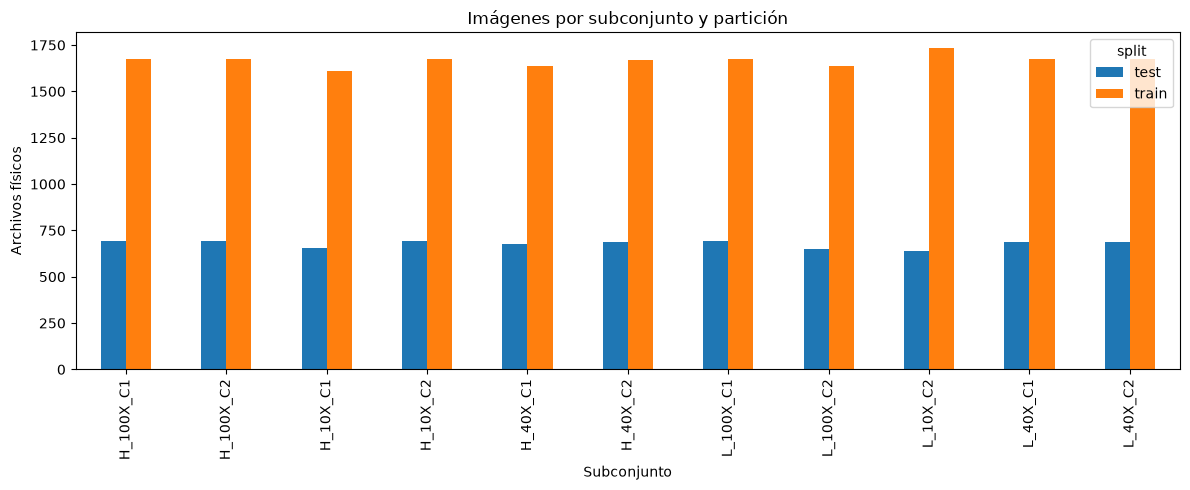

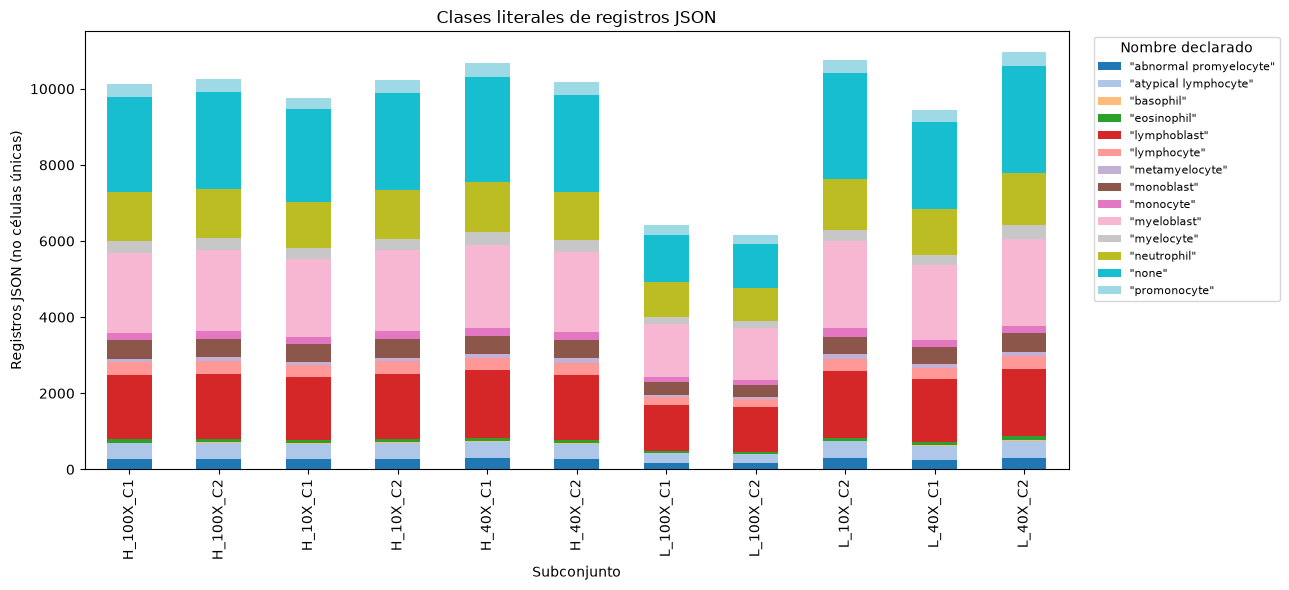

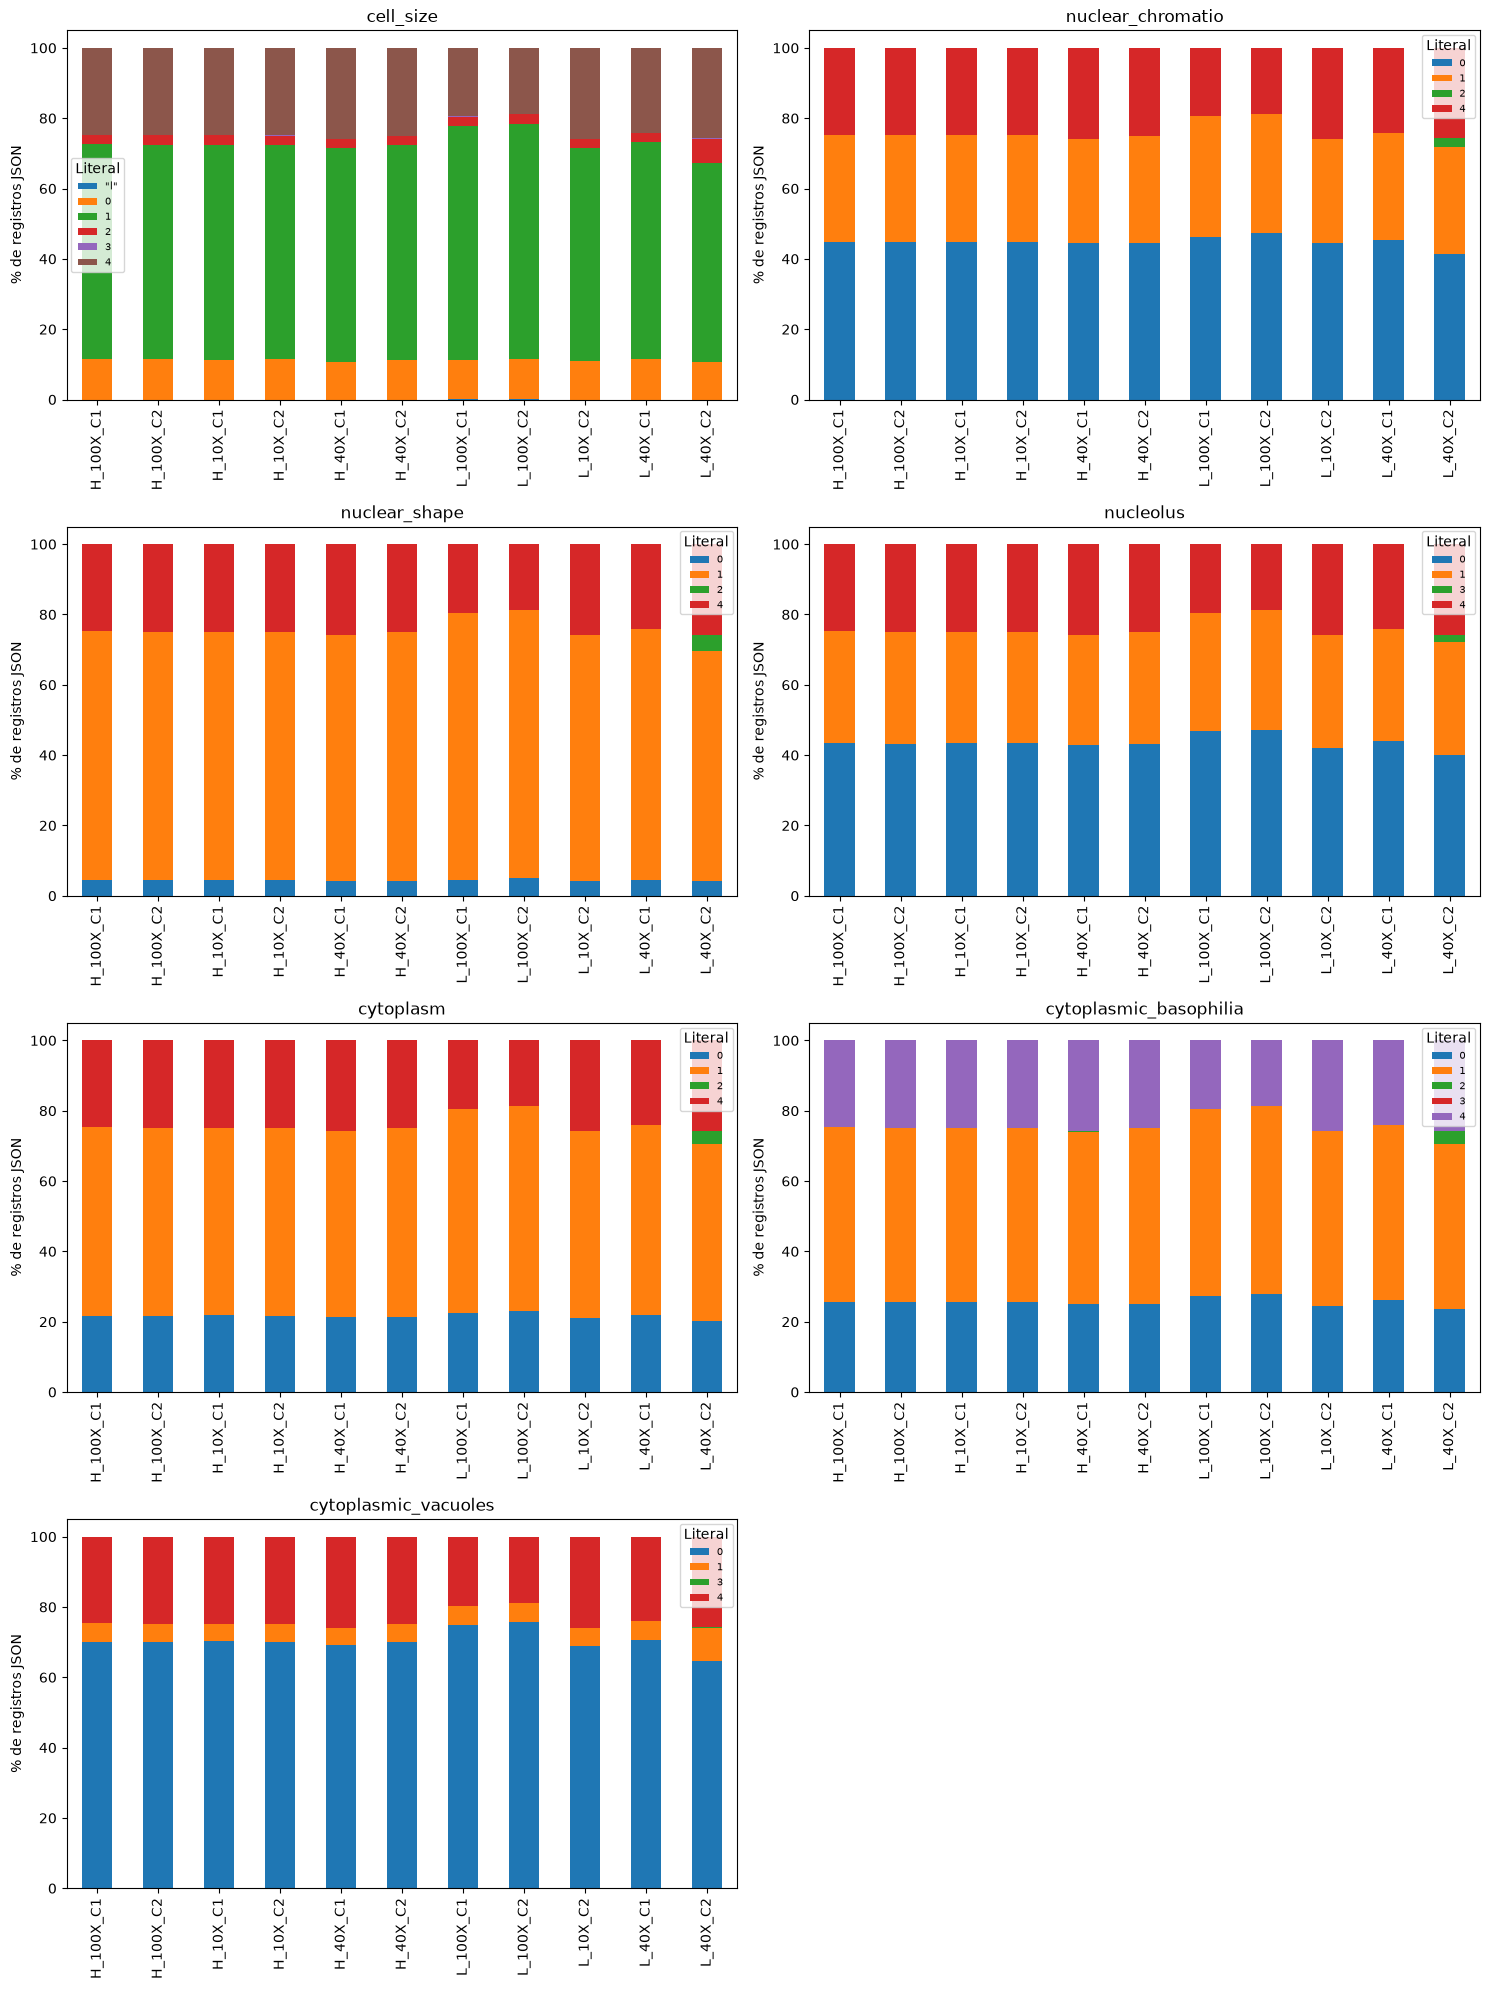

El nombre celular JSON más frecuente es **"none"**, con **25,606 registros**. Se observan **14 nombres JSON literales** y **14 tokens de clase TXT**; cantidades parecidas no establecen equivalencia de identificadores. Los diagnósticos por nombre describen archivos de campo y no deben sustituir a la clase de cada caja. Los códigos de atributos se mantienen sin adjudicar significado.

In [7]:
def diagnosis_from_filename(name):
    m=re.search(r'_([A-Za-z][A-Za-z0-9-]*)\.[^.]+$',name)
    return m.group(1) if m else '__NO_DERIVABLE__'
images['diagnosis_filename']=images.filename.map(diagnosis_from_filename)
info['diagnosis_filename']=info.filename.map(diagnosis_from_filename)
classfreq=anns.groupby(['subset','split','category_id_literal','category_name_literal','association']).agg(registros=('ann_uid','size'),firmas_candidatas_distintas=('candidate_signature','nunique')).reset_index()
diagnoses=images.groupby(['subset','split','diagnosis_filename']).size().reset_index(name='archivos_imagen')
attrfreq=[]
for a in ATTRS:
    f=anns.groupby(['subset','split',a],dropna=False).size().reset_index(name='registros_JSON').rename(columns={a:'valor_literal'});f['atributo']=a;attrfreq.append(f)
attrfreq=pd.concat(attrfreq,ignore_index=True)
txtclass=txt.groupby(['subset','split','schema','class_token']).size().reset_index(name='lineas_TXT')
txtattr=[]
for pos in range(1,8):
    f=txt[txt.n_columns.eq(12)].groupby(['subset','split',f'attr_p{pos}'],dropna=False).size().reset_index(name='lineas_TXT').rename(columns={f'attr_p{pos}':'token_literal'});f['posicion_atributo']=pos;txtattr.append(f)
txtattr=pd.concat(txtattr,ignore_index=True)
for name,df in [('imagenes_inventario',images),('imagenes_inspeccion',info),('json_clases_frecuencias',classfreq),('diagnosticos_derivados_nombre',diagnoses),('json_atributos_frecuencias',attrfreq),('txt_clases_literales',txtclass),('txt_atributos_posicionales',txtattr)]:save(name,df)
show(classfreq,20);show(diagnoses,20)
fig,ax=plt.subplots(figsize=(12,5));pd.crosstab(images.subset,images.split).plot.bar(ax=ax);ax.set(ylabel='Archivos físicos',xlabel='Subconjunto',title='Imágenes por subconjunto y partición');fig.tight_layout();fig.savefig(OUTPUT_DIR/'01_imagenes_particiones.png');plt.show()
fig,ax=plt.subplots(figsize=(13,6));ct=pd.crosstab(anns.subset,anns.category_name_literal);ct.plot.bar(stacked=True,ax=ax,colormap='tab20');ax.set(ylabel='Registros JSON (no células únicas)',xlabel='Subconjunto',title='Clases literales de registros JSON');ax.legend(title='Nombre declarado',bbox_to_anchor=(1.02,1),loc='upper left',fontsize=8);fig.tight_layout();fig.savefig(OUTPUT_DIR/'02_clases_json.png');plt.show()
fig,axes=plt.subplots(4,2,figsize=(15,20));axes=axes.ravel()
for ax,a in zip(axes,ATTRS):
    cc=pd.crosstab(anns.subset,anns[a]);cc=cc.div(cc.sum(axis=1),axis=0)*100;cc.plot.bar(stacked=True,ax=ax);ax.set(title=a,ylabel='% de registros JSON',xlabel='');ax.legend(title='Literal',fontsize=7)
for ax in axes[len(ATTRS):]:ax.axis('off')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'03_atributos_json.png');plt.show()
major=anns.category_name_literal.value_counts()
say(f'El nombre celular JSON más frecuente es **{major.index[0]}**, con **{major.iloc[0]:,} registros**. Se observan **{anns.category_name_literal.nunique()} nombres JSON literales** y **{txt.class_token.nunique()} tokens de clase TXT**; cantidades parecidas no establecen equivalencia de identificadores. Los diagnósticos por nombre describen archivos de campo y no deben sustituir a la clase de cada caja. Los códigos de atributos se mantienen sin adjudicar significado.')


## 7. Duplicados de imágenes y conflictos asociados

**Pregunta:** ¿hay igualdad exacta entre archivos, cruces de particiones y anotaciones discrepantes? **Método:** comparar SHA-256 de archivo y de matriz RGBA con tamaño. Componentes conectados unen ambos criterios: cada archivo pertenece como máximo a un grupo final, de modo que **los conteos por criterio no se suman**. Una colisión criptográfica es extremadamente improbable; no se detecta similitud aproximada.

Se compara por archivo el conjunto de firmas JSON de caja/clase/atributos sin identificadores administrativos. También se registra diferencia en cantidad bruta de registros y clases. Una discrepancia es un **conflicto candidato de anotación**, no prueba de que corresponda a células diferentes ni decisión sobre la anotación correcta. Se reportan cruces de subconjunto y de partición por separado. Esto no descarta relaciones por paciente/campo ni permite deducirlas.

**Aclaración posterior:** consultar la sección 12.2 antes de interpretar `False` como concordancia. Allí se añade el estado de comparabilidad manteniendo estos indicadores originales.

In [ ]:
parent={int(i):int(i) for i in info.image_uid}
def find(x):
    while parent[x]!=x:parent[x]=parent[parent[x]];x=parent[x]
    return x
def union(x,y):
    x,y=find(x),find(y)
    if x!=y:parent[y]=x
criteria=[]
for criterion in ['file_sha256','pixel_sha256']:
    gs=[g for _,g in info[info[criterion].notna()].groupby(criterion) if len(g)>1]
    criteria.append({'criterio':criterion,'grupos':len(gs),'archivos_participantes':sum(len(g) for g in gs)})
    for g in gs:
        ids=g.image_uid.tolist()
        for other in ids[1:]:union(int(ids[0]),int(other))
components=defaultdict(list)
for uid in parent:components[find(uid)].append(uid)
ann_by_image={int(uid):g for uid,g in anns[anns.association.eq('unica')].groupby('image_uid')}
patterns={};classsets={}
for uid,g in ann_by_image.items():
    signatures=sorted({literal([r['bbox_literal'],r['category_id_literal'],*[r[a] for a in ATTRS]]) for r in g.to_dict('records')})
    patterns[uid]=sha_bytes(literal(signatures).encode());classsets[uid]=literal(sorted(g.category_name_literal.unique()))
group_rows=[];member_rows=[]
for ids in sorted(components.values(),key=min):
    if len(ids)<2:continue
    gid=f'DUP_{len(group_rows)+1:05d}';g=info[info.image_uid.isin(ids)];annotated=[i for i in ids if i in patterns]
    row={'grupo':gid,'archivos':len(ids),'subconjuntos':','.join(sorted(g.subset.unique())),'particiones':','.join(sorted(g.split.unique())),'cruza_subconjuntos':g.subset.nunique()>1,'cruza_particiones':g.split.nunique()>1,'archivos_con_JSON':len(annotated),'conflicto_firmas_JSON':len({patterns[i] for i in annotated})>1,'conflicto_conjunto_clases':len({classsets[i] for i in annotated})>1,'difiere_numero_registros_JSON':len({len(ann_by_image[i]) for i in annotated})>1,'hashes_archivo_distintos':g.file_sha256.nunique(),'hashes_pixeles_distintos':g.pixel_sha256.nunique()}
    group_rows.append(row)
    for uid in ids:member_rows.append({'grupo':gid,'image_uid':uid,'physical_rel':info_by_uid[uid]['physical_rel']})
    if row['cruza_particiones'] or row['conflicto_firmas_JSON']:issue('duplicado_cruce_o_conflicto',gid,','.join(map(str,ids)),literal(row))
dupgroups=pd.DataFrame(group_rows,columns=['grupo','archivos','subconjuntos','particiones','cruza_subconjuntos','cruza_particiones','archivos_con_JSON','conflicto_firmas_JSON','conflicto_conjunto_clases','difiere_numero_registros_JSON','hashes_archivo_distintos','hashes_pixeles_distintos'])
dupmembers=pd.DataFrame(member_rows,columns=['grupo','image_uid','physical_rel'])
save('duplicados_criterios',pd.DataFrame(criteria));save('duplicados_grupos_unificados',dupgroups);save('duplicados_miembros',dupmembers)
display(pd.DataFrame(criteria));show(dupgroups,20)
say(f'La unión produce **{len(dupgroups)} grupos** y **{len(dupmembers)} archivos participantes**. **{int(dupgroups.cruza_particiones.sum()) if len(dupgroups) else 0} grupos cruzan particiones** y **{int(dupgroups.conflicto_firmas_JSON.sum()) if len(dupgroups) else 0} presentan conjuntos de anotaciones JSON distintos**. Ningún duplicado se elimina. No se descarta fuga por paciente ni parentesco entre campos.')


## 8. Captions de Arturo: asociación y límite celular

**Pregunta:** ¿a qué unidad se vinculan los textos y qué se puede comparar? **Método:** analizar las filas del CSV conservando un diagnóstico para todas. Una asociación requiere prefijo `data/archive/LeukemiaAttri_Dataset/`, subconjunto, ruta Images/partición, nombre final coherente, partición declarada coherente y un único archivo de la fuente principal. No se usan otras carpetas para resolver faltantes.

Se cuentan filas de captions, archivos cubiertos, textos literales distintos, filas repetidas y longitud (caracteres Unicode y palabras por espacios). No se asigna un caption de campo a sus cajas. `cell_type_idx` no se interpreta como un identificador de célula. Se revisa si el esquema ofrece `cell_id`, `annotation_id` o caja; sin esa referencia y sin diccionario de atributos validado, **no hay comparación celular justificable**.

Solo se contrasta la consistencia literal de metadatos de campo: diagnosis declarada frente al sufijo derivado, y magnification frente al token de carpeta. Eso no valida diagnósticos clínicos ni morfología. Compartir texto no demuestra igualdad de imágenes.

In [ ]:
cap=pd.read_csv(CAPTIONS_CSV,dtype=str,keep_default_na=False);cap_original=list(cap.columns);cap.insert(0,'caption_id',np.arange(len(cap)));cap['source_row']=np.arange(2,len(cap)+2)
def associate_caption(row):
    raw=row['image_path'].replace('\\','/');prefix='data/archive/LeukemiaAttri_Dataset/'
    result={'subset_path':'','split_path':'','association':'otra_fuente_o_prefijo','image_uid':None,'image_key':'','candidates_json':'[]'}
    if not raw.startswith(prefix):return result
    parts=PurePosixPath(raw[len(prefix):]).parts
    if len(parts)<4 or parts[1].casefold()!='images' or parts[2].casefold() not in {'train','test','val'}:result['association']='ruta_no_reconocida';return result
    subset,split=parts[0],parts[2].casefold();result.update(subset_path=subset,split_path=split)
    if row['filename']!=parts[-1]:result['association']='nombre_ruta_discrepante';return result
    if row['split'].casefold()!=split:result['association']='particion_declarada_discrepante';return result
    if row['dataset']!='LeukemiaAttri':result['association']='dataset_declarado_discrepante';return result
    result.update(associate(subset,split,'/'.join(parts[3:])))
    return result
cap=pd.concat([cap,pd.DataFrame([associate_caption(r) for r in cap.to_dict('records')])],axis=1)
selected=cap[cap.association.eq('unica')].copy();selected['characters']=selected.caption.str.len();selected['words']=selected.caption.str.split().str.len()
selected=selected.merge(images[['image_uid','diagnosis_filename','magnification_path']],on='image_uid',how='left',validate='many_to_one')
selected['diagnosis_literal_agrees']=selected.diagnosis.eq(selected.diagnosis_filename)
selected['magnification_literal_agrees']=selected.magnification.str.casefold().eq(selected.magnification_path.str.casefold())
cell_link_columns=[x for x in ['cell_id','annotation_id','bbox','x','y','width','height'] if x in cap_original]
# No hay un vínculo celular validado en este análisis, incluso si otra versión añadiera una columna.
selected['cell_comparison_status']='no_comparable_sin_vinculo_celular_y_diccionario_validado'
capcoverage=images[['image_uid','subset','split','physical_rel']].copy()
cc=selected.groupby('image_uid').agg(filas_captions=('caption_id','size'),textos_distintos=('caption','nunique'))
capcoverage=capcoverage.merge(cc,on='image_uid',how='left').fillna({'filas_captions':0,'textos_distintos':0})
textstats=selected.groupby('caption').agg(filas_captions=('caption_id','size'),archivos=('image_uid','nunique'),subconjuntos=('subset_path','nunique'),particiones=('split_path',lambda s:','.join(sorted(set(s))))).reset_index().sort_values('filas_captions',ascending=False)
repeatedcap=selected[selected.duplicated(cap_original,keep=False)]
capdist=selected.groupby(['subset_path','split_path']).agg(filas_captions=('caption_id','size'),archivos=('image_uid','nunique'),textos_distintos=('caption','nunique'),palabras_media=('words','mean')).reset_index()
declared=selected.groupby(['subset_path','split_path','diagnosis']).agg(filas_captions=('caption_id','size'),archivos=('image_uid','nunique')).reset_index()
for name,df in [('captions_diagnostico_completo',cap),('captions_asociados',selected),('captions_cobertura_imagen',capcoverage),('captions_distribucion',capdist),('captions_textos',textstats),('captions_filas_repetidas',repeatedcap),('diagnosticos_declarados_captions',declared)]:save(name,df)
display(cap.association.value_counts().rename_axis('asociacion').to_frame('filas_captions'));display(capdist);display(selected[['characters','words']].describe());show(textstats,8)
print('Columnas de vínculo celular presentes:',cell_link_columns)
for r in cap.loc[cap.dataset.eq('LeukemiaAttri')&cap.association.ne('unica')].to_dict('records'):issue('caption_asociacion_'+r['association'],str(CAPTIONS_CSV),r['source_row'],r['image_path'])
for r in selected.loc[~selected.diagnosis_literal_agrees|~selected.magnification_literal_agrees].to_dict('records'):issue('caption_metadato_campo_discrepante',str(CAPTIONS_CSV),r['source_row'],literal({x:r[x] for x in ['image_path','diagnosis','diagnosis_filename','magnification','magnification_path']}))
say(f'**{len(selected):,} filas de captions** se asocian a **{selected.image_uid.nunique():,} archivos** y contienen **{selected.caption.nunique()} textos distintos**. **{int(capcoverage.filas_captions.eq(0).sum())} archivos carecen de caption asociado**; **{len(repeatedcap):,} filas participan en repetición exacta**. No se identifica una célula concreta mediante estas rutas; **0 comparaciones morfológicas celulares están justificadas por este procedimiento**. Los textos pueden mencionar una célula singular, pero no indican a qué caja corresponde. Hay **{int((~selected.diagnosis_literal_agrees).sum())} discrepancias literales de diagnóstico de campo** y **{int((~selected.magnification_literal_agrees).sum())} de aumento**, sin adjudicación clínica.')


## 9. Ejemplos reproducibles de campos y cajas

**Pregunta:** ¿cómo se relacionan visualmente el campo, algunas anotaciones y sus captions? **Método:** por cada subconjunto con imágenes, elegir un campo por partición disponible mediante semilla fija sobre rutas ordenadas, prefiriendo campos legibles con alguna anotación JSON asociada. Se dibujan como máximo cinco cajas geométricamente válidas del campo, identificadas por nombre/id de categoría original; la procedencia y el índice de registro aparecen debajo. Si no hay cajas verificables, se muestra el campo sin ellas.

No se genera ningún recorte. El PDF guarda páginas de ejemplos completos con superposiciones; no es material de entrenamiento. Mostrar solo algunas cajas es una decisión de legibilidad, no una exclusión del dataset. **Resultado e interpretación:** los captions asociados se muestran como textos del campo; aun cuando describan una célula singular, no se señala una caja como su referente.

In [ ]:
example_rows=[];readable=set(info.loc[info.error.eq(''),'image_uid']);captions_by_image={int(uid):g for uid,g in selected.groupby('image_uid')}
with PdfPages(OUTPUT_DIR/'04_ejemplos_campos.pdf') as pdf:
    for si,subset in enumerate(all_subsets):
        available=info[info.subset.eq(subset)&info.image_uid.isin(readable)]
        if available.empty:say(f'**{subset}:** no hay archivos legibles disponibles para ejemplo.');continue
        chosen=[]
        for split,g in available.groupby('split',sort=True):
            annotated=g[g.image_uid.isin(ann_by_image)];pool=annotated if len(annotated) else g
            chosen.append(pool.sort_values('physical_rel').sample(1,random_state=SEED+si).iloc[0])
        fig,axes=plt.subplots(1,len(chosen),figsize=(6*len(chosen),6),squeeze=False)
        provenance=[]
        for ax,row in zip(axes.ravel(),chosen):
            uid=int(row.image_uid)
            with Image.open(ROOT/row.physical_rel) as im:ax.imshow(im.copy())
            annotations=ann_by_image.get(uid,anns.iloc[:0]);boxes=annotations[annotations.bbox_status.eq('valida_geometricamente')].sort_values(['source_id','record_index']).head(5)
            for ar in boxes.to_dict('records'):
                x,y,bw,bh=json.loads(ar['bbox_literal']);ax.add_patch(Rectangle((x,y),bw,bh,fill=False,edgecolor='yellow',linewidth=1.4));label=f"{json.loads(ar['category_name_literal'])} [id {ar['category_id_literal']}]";ax.text(x,y,label,fontsize=7,color='black',bbox={'facecolor':'yellow','alpha':.8,'pad':1})
                provenance.append({'image_uid':uid,'ann_uid':ar['ann_uid'],'source_id':ar['source_id'],'record_index':ar['record_index'],'source':source_lookup[ar['source_id']]['source']})
            ax.set_title(f'{subset} · {row.split}\n{row.filename}\n{len(boxes)} cajas mostradas / {len(annotations)} registros JSON',fontsize=10);ax.axis('off')
            example_rows.append({'image_uid':uid,'subset':subset,'split':row.split,'physical_rel':row.physical_rel,'seed':SEED+si,'n_boxes_displayed':len(boxes),'ann_uids':literal(boxes.ann_uid.tolist())})
        fig.tight_layout();pdf.savefig(fig,bbox_inches='tight');plt.show()
        for row in chosen:
            uid=int(row.image_uid);say(f'**Campo:** `{row.physical_rel}`')
            prov=pd.DataFrame([r for r in provenance if r['image_uid']==uid])
            if len(prov):
                with pd.option_context('display.max_colwidth',None):display(HTML(prov.to_html(index=False)))
            cg=captions_by_image.get(uid)
            if cg is None:say('No hay caption asociado inequívocamente a este campo.')
            else:
                for text,gg in cg.groupby('caption',sort=True):
                    say(f'**Caption de campo; {len(gg)} filas de la fuente; ids {gg.caption_id.tolist()}:**')
                    display(HTML('<p style="white-space:pre-wrap;overflow-wrap:anywhere">'+escape(text)+'</p>'))
                say('**Ambigüedad:** no se conoce qué célula/caja describe este texto; no se asignó a las cajas mostradas.')
save('ejemplos_visuales',pd.DataFrame(example_rows))
say(f'Se muestran **{len(example_rows)} campos**, seleccionados reproduciblemente. Las superposiciones son explicativas y mantienen las etiquetas originales, sin corregir morfología.')


## 10. Resumen específico de H_100X_C2

**Pregunta:** ¿qué aporta H_100X_C2 respecto al conjunto disponible? **Método:** calcular las mismas unidades, correspondencias y controles restringidos a ese subconjunto, y compararlas con cada subconjunto. Se muestra su distribución celular y los códigos de atributos tal como aparecen.

El [repositorio de referencia](https://github.com/AndresGDS/TrabajoTerminal-Prediagnostico-leucemia) utiliza esta selección. Esto no demuestra que sea clínicamente superior, ni valida códigos del repositorio. **Resultado e interpretación:** su aporte comprobable es el volumen y cobertura observados, la configuración declarada en el nombre y las incidencias verificadas; decidir usarlo para entrenamiento sigue pendiente.

In [ ]:
subset_summary=[]
for subset in all_subsets:
    im=info[info.subset.eq(subset)];rr=refs[refs.subset.eq(subset)];aa=anns[anns.subset.eq(subset)];tt=txt[txt.subset.eq(subset)];cc=selected[selected.subset_path.eq(subset)]
    subset_summary.append({'subset':subset,'archivos_imagen':len(im),'referencias_JSON':len(rr),'rutas_JSON_distintas':rr.image_key.nunique(),'registros_JSON':len(aa),'firmas_candidatas_JSON':aa.candidate_signature.nunique(),'JSON_asociaciones_no_unicas':int(aa.association.ne('unica').sum()),'lineas_TXT_5':int(tt.n_columns.eq(5).sum()),'lineas_TXT_12':int(tt.n_columns.eq(12).sum()),'filas_captions':len(cc),'archivos_con_caption':cc.image_uid.nunique(),'textos_distintos':cc.caption.nunique(),'errores_lectura':int(im.error.ne('').sum())})
subset_summary=pd.DataFrame(subset_summary);save('resumen_subconjuntos',subset_summary);display(subset_summary)
focus_images=info[info.subset.eq(FOCUS)];focus_anns=anns[anns.subset.eq(FOCUS)];focus_refs=refs[refs.subset.eq(FOCUS)];focus_caps=selected[selected.subset_path.eq(FOCUS)]
display(subset_summary[subset_summary.subset.eq(FOCUS)].T)
display(pd.crosstab(focus_anns.category_name_literal,focus_anns.split))
display(attr_coverage[attr_coverage.subset.eq(FOCUS)])
focus_frequencies=attrfreq[attrfreq.subset.eq(FOCUS)];show(focus_frequencies,100);save('H_100X_C2_atributos',focus_frequencies)
focus_dup_groups=set(dupmembers.loc[dupmembers.image_uid.isin(focus_images.image_uid),'grupo'])
focus_duplicates=dupgroups[dupgroups.grupo.isin(focus_dup_groups)];show(focus_duplicates,20)
say(f'**{FOCUS} aporta {len(focus_images):,} archivos ({len(focus_images)/len(info):.2%} de la fuente principal)**, **{len(focus_refs):,} referencias JSON**, **{len(focus_anns):,} registros JSON** y **{len(focus_caps):,} filas de captions**. Participa en **{len(focus_dup_groups)} grupos de imágenes duplicadas**. Su nombre declara 100X/C2, sin identificar pacientes. Los atributos son códigos originales, no una traducción validada a lenguaje morfológico. Estos resultados describen cobertura, no prioridad clínica o aptitud automática para entrenar.')


## 11. Conclusiones, limitaciones, incidencias y verificación

**Pregunta:** ¿qué está comprobado y qué decisiones siguen abiertas? **Método:** sintetizar exclusivamente los resultados de esta ejecución y comprobar identidades de conteo, fuentes documentales, hashes de fuentes y conservación de WBCAtt. Las incidencias completas se guardan con archivo y registro originales (índices JSON desde cero; líneas TXT y filas CSV desde uno, encabezado CSV en fila uno).

Las propuestas no se aplican: revisar referencias repetidas, cajas y faltantes; documentar diccionarios y procedencia; resolver duplicados con una política de particiones; y establecer la unidad de caption antes de cualquier reconstrucción. No se presenta un dataset final validado.

**Lectura de estas conclusiones:** se conserva la salida de la ejecución completa de origen. La sección 12 añade las precisiones posteriores y actualiza el resumen tabular, sin repetir aquella inspección.

In [12]:
incidents=pd.DataFrame(issues,columns=['tipo','fuente','registro','detalle']);save('incidencias',incidents)
display(incidents.tipo.value_counts().rename_axis('tipo').to_frame('incidencias'))
show(incidents[incidents.tipo.eq('TXT_token_no_numerico_conservado')],20)
invalid_json=anns[~anns.bbox_status.isin(['valida_geometricamente','limites_no_verificables'])]
summary={'archivos_imagen':len(info),'subconjuntos_con_imagenes':info.subset.nunique(),'ubicaciones_JSON':int(sources.format.eq('json').sum()),'documentos_JSON_representantes':int((sources.format.eq('json')&sources.is_canonical).sum()),'ubicaciones_TXT':int(sources.format.eq('txt').sum()),'documentos_TXT_representantes':int((sources.format.eq('txt')&sources.is_canonical).sum()),'referencias_JSON':len(refs),'referencias_JSON_asociacion_unica':int(refs.association.eq('unica').sum()),'referencias_JSON_asociacion_faltante':int(refs.association.eq('faltante').sum()),'registros_JSON':len(anns),'registros_JSON_asociacion_unica':int(anns.association.eq('unica').sum()),'registros_JSON_cajas_invalidas':len(invalid_json),'registros_JSON_limites_no_verificables':int(anns.bbox_status.eq('limites_no_verificables').sum()),'lineas_TXT_5':int(txt.n_columns.eq(5).sum()),'lineas_TXT_12':int(txt.n_columns.eq(12).sum()),'lineas_TXT_otras':int((~txt.n_columns.isin([5,12])).sum()),'errores_lectura_imagen':int(info.error.ne('').sum()),'advertencias_imagen':int(info.warning.ne('').sum()),'grupos_duplicados_unificados':len(dupgroups),'grupos_cruzan_particiones':int(dupgroups.cruza_particiones.sum()) if len(dupgroups) else 0,'grupos_conflicto_firmas_JSON':int(dupgroups.conflicto_firmas_JSON.sum()) if len(dupgroups) else 0,'filas_captions_asociadas':len(selected),'archivos_con_caption':selected.image_uid.nunique(),'textos_captions_distintos':selected.caption.nunique(),'comparaciones_morfologicas_celulares_justificadas':0}
sumdf=pd.Series(summary,name='resultado').rename_axis('medida').reset_index();save('resumen',sumdf);display(sumdf)
say(f"""**Comprobado en esta ejecución.** La fuente principal contiene {len(info):,} imágenes de {info.subset.nunique()} subconjuntos. Tras agrupar copias documentales, hay {len(refs):,} referencias JSON y {len(anns):,} registros de anotación JSON. Las {len(txt):,} líneas TXT son otra representación y no se suman como células. Las referencias repetidas y firmas coincidentes se conservan y se distinguen de archivos y células biológicas.

**Correspondencias y geometría.** {int(refs.association.eq('unica').sum()):,} referencias JSON tienen archivo único; {int(refs.association.ne('unica').sum()):,} no. Hay {len(invalid_json):,} registros JSON con caja geométricamente inválida y {int(anns.bbox_status.eq('limites_no_verificables').sum()):,} sin límites verificables. Las pruebas del lector no prueban exactitud de las etiquetas ni de las cajas.

**Imágenes y particiones.** {int(info.error.ne('').sum())} errores de decodificación y {int(info.warning.ne('').sum())} archivos con advertencias. Se obtuvieron {len(dupgroups)} grupos unificados de duplicados exactos, {int(dupgroups.cruza_particiones.sum()) if len(dupgroups) else 0} con cruce de partición y {int(dupgroups.conflicto_firmas_JSON.sum()) if len(dupgroups) else 0} con conjuntos de anotaciones JSON diferentes. No se sumaron criterios ni se infirió independencia por paciente/campo.

**Captions.** {len(selected):,} filas se asocian a {selected.image_uid.nunique():,} archivos y usan {selected.caption.nunique()} textos distintos. La fuente no ofrece aquí un vínculo validado a una célula concreta; no se copiaron captions a sus cajas ni se compararon códigos morfológicos sin diccionario. Diagnosis declarada o derivada del nombre es metadato de campo, no clase celular ni diagnóstico clínico verificado.

**H_100X_C2.** Sus {len(focus_images):,} archivos y {len(focus_anns):,} registros JSON permiten describir su cobertura local. Su uso por el repositorio es una decisión de referencia, no validación de calidad o de diccionarios.

**Pendientes antes de preparar datos:** revisar las incidencias trazables, documentar convenciones TXT y códigos (incluido cualquier token no numérico), distinguir repeticiones de anotación de células distintas, resolver identidad entre representaciones, evaluar duplicados aproximados y relaciones por paciente/campo, y definir si el texto objetivo será de campo o de célula. Ninguna limpieza, exclusión o cambio de partición se aplicó. No se reconstruyó un dataset final ni se buscaron nuevas fuentes.""")
assert len(info)==len(images)==info.image_uid.nunique()
assert len(refs)==doc_stats.loc[doc_stats.format.eq('json'),'n_refs'].sum()
assert len(anns)==doc_stats.loc[doc_stats.format.eq('json'),'n_annotations'].sum()
assert len(txt)==doc_stats.loc[doc_stats.format.eq('txt'),'n_lines'].sum()
assert set(sources.canonical_source)<=set(sources.source_id)
assert len(dupmembers)==dupmembers.image_uid.nunique()
assert capcoverage.filas_captions.sum()==len(selected)
assert subset_summary.archivos_imagen.sum()==len(images)
assert subset_summary.registros_JSON.sum()==len(anns)
for source,digest in source_hashes.items():assert sha(source)==digest,'Fuente de anotación/captions cambió: '+source
protection=[]
for path,digest in protected_before.items():
    current=sha(path);assert current==digest,'Archivo WBCAtt/inventario cambiado: '+path
    protection.append({'ruta':path,'sha256_antes':digest,'sha256_despues':current,'sin_cambios':True})
save('verificacion_proteccion_wbcatt',pd.DataFrame(protection));save('fuentes_hashes',pd.DataFrame([{'ruta':p,'sha256':h} for p,h in source_hashes.items()]));save('ejecucion',pd.DataFrame([{'utc':run_utc,'python':sys.version,'semilla':SEED,'root':str(ROOT)}]))
with closing(sqlite3.connect(DB)) as con:
    assert con.execute('PRAGMA integrity_check').fetchone()[0]=='ok'
    tables=pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name",con)
say('**Verificaciones superadas:** conteos coherentes; fuentes de anotación y captions sin cambios por hash; notebook, respaldo, resultados WBCAtt e inventario intactos; SQLite íntegra. Las salidas pertenecen a esta ejecución. Estas comprobaciones no validan exactitud clínica.')
display(tables);print('Documento principal: 02_EDA_LeukemiaAttri.ipynb');print('Tablas completas:',DB)


,incidencias
tipo,
TXT_caja_condicional_extension_fuera_limites,2425
TXT_caja_condicional_tamano_no_positivo,451
TXT_caja_condicional_origen_fuera_limites,329
TXT_linea_repetida,249
TXT_linea_asociacion_faltante,194
JSON_firma_celular_repetida_candidata,86
JSON_caja_tamano_no_positivo,49
JSON_caja_extension_fuera_limites,23
duplicado_cruce_o_conflicto,5


,medida,resultado
0,archivos_imagen,25790
1,subconjuntos_con_imagenes,11
2,ubicaciones_JSON,26
3,documentos_JSON_representantes,22
4,ubicaciones_TXT,51582
5,documentos_TXT_representantes,45911
6,referencias_JSON,32042
7,referencias_JSON_asociacion_unica,32042
8,referencias_JSON_asociacion_faltante,0
9,registros_JSON,104941


**Comprobado en esta ejecución.** La fuente principal contiene 25,790 imágenes de 11 subconjuntos. Tras agrupar copias documentales, hay 32,042 referencias JSON y 104,941 registros de anotación JSON. Las 187,893 líneas TXT son otra representación y no se suman como células. Las referencias repetidas y firmas coincidentes se conservan y se distinguen de archivos y células biológicas.

**Correspondencias y geometría.** 32,042 referencias JSON tienen archivo único; 0 no. Hay 72 registros JSON con caja geométricamente inválida y 0 sin límites verificables. Las pruebas del lector no prueban exactitud de las etiquetas ni de las cajas.

**Imágenes y particiones.** 0 errores de decodificación y 0 archivos con advertencias. Se obtuvieron 15 grupos unificados de duplicados exactos, 3 con cruce de partición y 5 con conjuntos de anotaciones JSON diferentes. No se sumaron criterios ni se infirió independencia por paciente/campo.

**Captions.** 51,560 filas se asocian a 25,780 archivos y usan 75 textos distintos. La fuente no ofrece aquí un vínculo validado a una célula concreta; no se copiaron captions a sus cajas ni se compararon códigos morfológicos sin diccionario. Diagnosis declarada o derivada del nombre es metadato de campo, no clase celular ni diagnóstico clínico verificado.

**H_100X_C2.** Sus 2,369 archivos y 10,256 registros JSON permiten describir su cobertura local. Su uso por el repositorio es una decisión de referencia, no validación de calidad o de diccionarios.

**Pendientes antes de preparar datos:** revisar las incidencias trazables, documentar convenciones TXT y códigos (incluido cualquier token no numérico), distinguir repeticiones de anotación de células distintas, resolver identidad entre representaciones, evaluar duplicados aproximados y relaciones por paciente/campo, y definir si el texto objetivo será de campo o de célula. Ninguna limpieza, exclusión o cambio de partición se aplicó. No se reconstruyó un dataset final ni se buscaron nuevas fuentes.

**Verificaciones superadas:** conteos coherentes; fuentes de anotación y captions sin cambios por hash; notebook, respaldo, resultados WBCAtt e inventario intactos; SQLite íntegra. Las salidas pertenecen a esta ejecución. Estas comprobaciones no validan exactitud clínica.

,name
0,H_100X_C2_atributos
1,anotaciones_conteos_documentales
2,anotaciones_fuentes
3,archivos_fisicos
4,atributos_cobertura
5,captions_asociados
6,captions_cobertura_imagen
7,captions_diagnostico_completo
8,captions_distribucion
9,captions_filas_repetidas


## 12. Actualización parcial de cobertura, duplicados y geometría — 2026-10-11

**Pregunta:** ¿qué significan exactamente los casos sin JSON, los indicadores de conflicto y las incidencias geométricas? **Método:** consultar las tablas de la ejecución de origen identificada abajo. Se reutilizan inventario, asociaciones, registros originales, estadísticas documentales, grupos de duplicados e incidencias. No se abren imágenes, ZIP ni captions; no se vuelven a decodificar ni se recalculan hashes de imágenes. Los resultados describen esa instantánea, no aseguran que los archivos originales sigan iguales hoy.

**Requisitos de reproducción:** para repetir solo esta actualización, ejecutar todas las celdas de la sección 12, en orden, con la SQLite existente y las tablas/columnas comprobadas en la primera celda. `ACTUALIZACION_DB` puede configurarse allí; en una ejecución completa se utiliza `DB`, configurado al principio. Si faltan tablas de origen, la actualización se detiene; no reconstruye silenciosamente resultados. Ejecutar el notebook completo sigue siendo posible: las secciones 1–11 generan las tablas y esta sección consume la ejecución que acaban de producir. **En esta actualización únicamente se ejecutó la sección 12.** Las salidas anteriores se mantienen como registro de la ejecución completa de origen.

**Registro de cambios:** se distinguen referencia, registro y documento; se añade un estado explícito a cada grupo de duplicados sin borrar indicadores previos; se desglosan incidencias por representación, subconjunto y partición, con ejemplos originales. Se añaden métricas al resumen y se comprueba que las columnas de origen utilizadas no cambien. Respaldo único previo: `02_EDA_LeukemiaAttri.ipynb.bak`. No se aplican limpieza, recortes, ajustes de cajas ni exclusiones.

In [ ]:
from pathlib import Path
from contextlib import closing
from datetime import datetime, timezone
from collections import defaultdict
import sqlite3, json, hashlib
import pandas as pd
from IPython.display import display, Markdown, HTML
# RUTA CONFIGURABLE PARA EJECUCIÓN PARCIAL; una ejecución completa hereda DB.
import sys
# Configurar HEMVLM_EDA_*; ver docs/eda/README.md.
HERE=Path.cwd().resolve()
REPO_ROOT=next((p for p in [HERE,*HERE.parents] if (p/'notebooks/eda/eda_paths.py').is_file()),None)
assert REPO_ROOT is not None, 'Iniciar desde el repositorio o notebooks/eda'
sys.path.insert(0,str(REPO_ROOT/'notebooks/eda'))
from eda_paths import eda_paths
EDA_PATHS=eda_paths()
DATASET_DIR=EDA_PATHS['dataset']
ACTUALIZACION_DB=Path(globals().get('DB',EDA_PATHS['revision_db']))
assert ACTUALIZACION_DB.is_file(), 'Falta la SQLite de origen: ejecutar primero el EDA completo o configurar la ruta.'
_revision_utc=datetime.now(timezone.utc).isoformat()
def rshow(df):display(HTML(df.to_html(index=False,escape=True,max_rows=None,max_cols=None)))
def rsay(text):display(Markdown(text))
def rread(query):
    with closing(sqlite3.connect(ACTUALIZACION_DB)) as con:
        con.execute('PRAGMA temp_store=MEMORY');return pd.read_sql_query(query,con)
def rsave(name,df):
    with closing(sqlite3.connect(ACTUALIZACION_DB)) as con:df.to_sql(name,con,if_exists='replace',index=False)
required={
 'ejecucion':['utc','root'], 'resumen':['medida','resultado'],
 'imagenes_inventario':['image_uid','subset','split','physical_rel','relative_image'],
 'cobertura_por_imagen':['image_uid','referencias_JSON','registros_JSON','lineas_TXT_5','lineas_TXT_12'],
 'anotaciones_fuentes':['source_id','source','subset','split','format','is_canonical','canonical_source','expected_image'],
 'documentos_estadisticas':['source_id','format','n_lines'],
 'json_referencias':['source_id','ref_uid','image_uid','association'],
 'json_anotaciones':['source_id','ann_uid','record_index','image_uid','association','bbox_literal','bbox_status','category_id_literal','cell_size','nuclear_chromatio','nuclear_shape','nucleolus','cytoplasm','cytoplasmic_basophilia','cytoplasmic_vacuoles'],
 'txt_registros':['source_id','txt_uid','line_no','image_uid','association','n_columns','tokens_json','original_line','bbox_status_conditional'],
 'duplicados_miembros':['grupo','image_uid','physical_rel'],
 'duplicados_grupos_unificados':['grupo','archivos','subconjuntos','particiones','cruza_subconjuntos','cruza_particiones','archivos_con_JSON','conflicto_firmas_JSON','conflicto_conjunto_clases','difiere_numero_registros_JSON','hashes_archivo_distintos','hashes_pixeles_distintos'],
 'incidencias':['tipo','fuente','registro','detalle']}
with closing(sqlite3.connect(ACTUALIZACION_DB)) as con:
    for table,columns in required.items():
        actual=[r[1] for r in con.execute('PRAGMA table_info("'+table+'")')]
        assert set(columns)<=set(actual),f'Tabla/columnas requeridas ausentes: {table}'
origin=rread('SELECT * FROM ejecucion');assert len(origin)==1,'Se requiere una ejecución de origen inequívoca'
origin_utc=origin.iloc[0]['utc'];rsay('**Ejecución de origen de las tablas:**');rshow(origin)
print('Actualización parcial UTC:',_revision_utc);print('SQLite:',ACTUALIZACION_DB)
# Firma de columnas originales. En duplicados se excluyen columnas nuevas de una revisión previa.
def table_digest(table,columns=None):
    h=hashlib.sha256();count=0
    with closing(sqlite3.connect(ACTUALIZACION_DB)) as con:
        cols=columns or [r[1] for r in con.execute('PRAGMA table_info("'+table+'")')]
        h.update(json.dumps(cols).encode())
        query='SELECT '+','.join('"'+c+'"' for c in cols)+' FROM "'+table+'" ORDER BY rowid'
        for row in con.execute(query):
            h.update((json.dumps(row,ensure_ascii=False,separators=(',',':'))+'\n').encode());count+=1
    return h.hexdigest(),count
input_tables=[t for t in required if t!='resumen']
digest_columns={'duplicados_grupos_unificados':required['duplicados_grupos_unificados']}
before={t:table_digest(t,digest_columns.get(t)) for t in input_tables}
summary_before=rread('SELECT * FROM resumen')
rimages=rread('SELECT * FROM imagenes_inventario');rcoverage=rread('SELECT * FROM cobertura_por_imagen')
rsources=rread('SELECT * FROM anotaciones_fuentes');rdocs=rread('SELECT * FROM documentos_estadisticas')
rrefs=rread('SELECT * FROM json_referencias');ranns=rread('SELECT * FROM json_anotaciones');rtxt=rread('SELECT * FROM txt_registros')
rgroup=rread('SELECT '+','.join(required['duplicados_grupos_unificados'])+' FROM duplicados_grupos_unificados')
rmembers=rread('SELECT * FROM duplicados_miembros')
rsay('**Reutilización explícita:** todas las referencias, cajas, asociaciones y duplicados siguientes proceden de estas tablas. Las firmas anteriores comprueban conservación de tablas, no vigencia de los archivos de imagen en disco. No se ha hecho una inspección nueva.')


### 12.1. Imágenes sin registros JSON asociados

**Pregunta:** ¿faltan referencias, anotaciones o documentos? **Método:** recalcular referencias y registros asociados inequívocamente desde sus tablas y contrastarlos con `cobertura_por_imagen`. Vincular los documentos TXT por subconjunto, partición y ruta relativa esperada, nunca por nombre aislado. Su estado vacío se obtiene de `documentos_estadisticas.n_lines`; significa cero líneas no vacías, no necesariamente cero bytes. Las copias documentales se cuentan como ubicaciones y sus representantes como documentos distintos. Si no hay documento localizado, no se afirma que exista un documento vacío.

**Resultado:** se presentan todas las imágenes que cumplan el criterio actual; no se fija el número 21 en el filtro. **Interpretación:** ausencia de registro no equivale a ausencia de documento; la presencia TXT se mantiene separada de JSON.

In [ ]:
recomputed=rimages[['image_uid','subset','split','physical_rel']].copy()
for name,frame in [('referencias_JSON',rrefs),('registros_JSON',ranns),('lineas_TXT_5',rtxt[rtxt.n_columns.eq(5)]),('lineas_TXT_12',rtxt[rtxt.n_columns.eq(12)])]:
    counts=frame[frame.association.eq('unica')].groupby('image_uid').size()
    recomputed[name]=recomputed.image_uid.map(counts).fillna(0).astype(int)
    expected=rcoverage.set_index('image_uid')[name].reindex(recomputed.image_uid).to_numpy()
    assert (recomputed[name].to_numpy()==expected).all(), 'Cobertura incompatible con sus registros: '+name
all_txt_counts=rtxt[rtxt.association.eq('unica')].groupby('image_uid').size()
recomputed['lineas_TXT_todas']=recomputed.image_uid.map(all_txt_counts).fillna(0).astype(int)
lookup=defaultdict(list)
for r in rimages.to_dict('records'):lookup[(r['subset'],r['split'],r['relative_image'])].append(r['image_uid'])
doc_links=[]
for r in rsources[rsources['format'].eq('txt')].to_dict('records'):
    candidates=lookup.get((r['subset'],r['split'],r['expected_image']),[])
    doc_links.append({'source_id':r['source_id'],'canonical_source':r['canonical_source'],'source':r['source'],'image_uid':candidates[0] if len(candidates)==1 else None,'association_doc':'unica' if len(candidates)==1 else 'ambigua' if candidates else 'faltante'})
doc_links=pd.DataFrame(doc_links)
stats=rdocs[rdocs['format'].eq('txt')][['source_id','n_lines']].rename(columns={'source_id':'canonical_source'})
assert stats.canonical_source.is_unique
doc_links=doc_links.merge(stats,on='canonical_source',how='left',validate='many_to_one')
unique_docs=doc_links[doc_links.association_doc.eq('unica')].drop_duplicates(['image_uid','canonical_source'])
for column,frame in [('documentos_TXT',unique_docs),('documentos_TXT_vacios',unique_docs[unique_docs.n_lines.eq(0)]),('documentos_TXT_estado_desconocido',unique_docs[unique_docs.n_lines.isna()]),('ubicaciones_TXT',doc_links[doc_links.association_doc.eq('unica')])]:
    counts=frame.groupby('image_uid').size();recomputed[column]=recomputed.image_uid.map(counts).fillna(0).astype(int)
missing=recomputed[recomputed.registros_JSON.eq(0)].copy()
missing['estado_JSON']=missing.referencias_JSON.map(lambda n:'referencia_existente_sin_registros' if n>0 else 'ausencia_de_referencia_JSON')
missing['estado_registros']=missing.lineas_TXT_todas.map(lambda n:'anotaciones_TXT_presentes' if n>0 else 'sin_registros_JSON_ni_TXT_asociados')
def doc_state(r):
    if r.documentos_TXT==0:return 'sin_documento_TXT_asociado'
    if r.documentos_TXT_estado_desconocido:return 'estado_documental_incompleto'
    if r.documentos_TXT_vacios:return 'hay_documento_TXT_vacio'
    return 'documentos_TXT_presentes_no_vacios'
missing['estado_documento_TXT']=missing.apply(doc_state,axis=1)
rsave('revision_sin_json_detalle',missing);rsave('revision_txt_documentos_asociacion',doc_links)
rshow(missing)
missing_summary=missing.groupby(['subset','split','estado_JSON','estado_registros','estado_documento_TXT']).size().reset_index(name='imagenes')
rsave('revision_sin_json_resumen',missing_summary);rshow(missing_summary)
n_ref_no_ann=int(missing.referencias_JSON.gt(0).sum());n_no_ref=int(missing.referencias_JSON.eq(0).sum());n_txt=int(missing.lineas_TXT_todas.gt(0).sum());n_neither=int(missing.lineas_TXT_todas.eq(0).sum())
assert n_ref_no_ann+n_no_ref==len(missing) and n_txt+n_neither==len(missing)
rsay(f'**Interpretación:** {len(missing)} imágenes carecen de registros JSON asociados: {n_no_ref} no tienen referencia JSON y {n_ref_no_ann} tienen referencia pero no anotaciones. {n_txt} tienen registros TXT; {n_neither} no tienen registros asociados en ninguna representación. Entre estas imágenes se localizaron {int(missing.documentos_TXT_vacios.sum())} documentos TXT vacíos y {int(missing.documentos_TXT_estado_desconocido.sum())} documentos de estado no comprobable. La conclusión se limita a asociaciones inequívocas dentro de las tablas de origen, no a la inexistencia absoluta de archivos externos.')


### 12.2. Comparabilidad de los grupos duplicados

**Pregunta:** ¿`False` significa coincidencia o falta de cobertura? **Método:** reconstruir para cada archivo el conjunto de firmas literales `(bbox, category_id, siete atributos)` usado en el EDA, sin IDs administrativos. La comparación de conjuntos ignora multiplicidad; el indicador anterior de cantidad de registros se conserva. Se considera comparable un grupo solo si todos sus miembros tienen registros JSON asociados inequívocamente. No se exige que sus cajas sean geométricamente válidas para comparar los valores declarados; esta comparación no valida morfología.

**Estados:** conjuntos diferentes, conjuntos coincidentes o cobertura JSON incompleta/no comparable. Los indicadores anteriores se conservan y se comprueban contra el cálculo original; un `False` en conflicto no se transforma automáticamente en concordancia. Se muestran todos los miembros, con nombres, rutas y particiones.

In [ ]:
rattrs=['cell_size','nuclear_chromatio','nuclear_shape','nucleolus','cytoplasm','cytoplasmic_basophilia','cytoplasmic_vacuoles']
member_ids=set(rmembers.image_uid)
ann_members=ranns[ranns.association.eq('unica')&ranns.image_uid.isin(member_ids)]
signatures={};raw_counts={}
for uid,g in ann_members.groupby('image_uid'):
    signatures[int(uid)]=frozenset(tuple(row) for row in g[['bbox_literal','category_id_literal',*rattrs]].itertuples(index=False,name=None))
    raw_counts[int(uid)]=len(g)
member_detail=rmembers.merge(rimages[['image_uid','subset','split','filename']],on='image_uid',validate='many_to_one')
member_detail['registros_JSON']=member_detail.image_uid.map(raw_counts).fillna(0).astype(int)
member_detail['firmas_JSON_distintas']=member_detail.image_uid.map(lambda uid:len(signatures.get(int(uid),[])))
comparison=[]
for r in rgroup.to_dict('records'):
    g=member_detail[member_detail.grupo.eq(r['grupo'])];ids=g.image_uid.astype(int).tolist();covered=[uid for uid in ids if uid in signatures]
    assert len(ids)==r['archivos'] and len(covered)==r['archivos_con_JSON']
    different=len({signatures[uid] for uid in covered})>1
    assert bool(r['conflicto_firmas_JSON'])==different
    status='no_comparable_cobertura_JSON_incompleta' if len(covered)!=len(ids) else 'conjuntos_JSON_diferentes' if different else 'conjuntos_JSON_coincidentes'
    comparison.append({**r,'estado_comparacion_JSON':status,'miembros_sin_registros_JSON':len(ids)-len(covered),'miembros_archivos_particiones':json.dumps(g[['filename','subset','split','registros_JSON']].to_dict('records'),ensure_ascii=False)})
comparison=pd.DataFrame(comparison)
# Conservar todas las columnas históricas y añadir explícitamente el estado.
rsave('duplicados_grupos_unificados',comparison)
member_detail=member_detail.merge(comparison[['grupo','estado_comparacion_JSON']],on='grupo',validate='many_to_one')
rsave('revision_duplicados_miembros',member_detail)
rshow(comparison[['grupo','archivos','archivos_con_JSON','conflicto_firmas_JSON','difiere_numero_registros_JSON','estado_comparacion_JSON','miembros_archivos_particiones']]);rshow(member_detail)
comparison_counts=comparison.estado_comparacion_JSON.value_counts().reindex(['conjuntos_JSON_diferentes','conjuntos_JSON_coincidentes','no_comparable_cobertura_JSON_incompleta'],fill_value=0).rename_axis('estado').reset_index(name='grupos')
rsave('revision_duplicados_resumen',comparison_counts);rshow(comparison_counts)
assert comparison_counts.grupos.sum()==len(rgroup)
rsay('**Interpretación:** los grupos de cobertura incompleta no aportan evidencia de concordancia. Las diferencias son discrepancias entre conjuntos declarados, sin decidir qué fuente es correcta. No se alteran imágenes, anotaciones, grupos ni particiones.')


### 12.3. Incidencias geométricas: registros, imágenes y documentos

**Pregunta.** ¿Cómo se distribuyen las cajas señaladas y cuántas imágenes y documentos representan?

**Método.** Se agrupan los estados geométricos ya calculados, por representación, tipo, subconjunto y partición; se cotejan sus sumas con `incidencias`. Los estados conservan la prioridad del lector original: una caja puede infringir varias condiciones pero figura una sola vez bajo el primer estado detectado. Los recuentos de imágenes/documentos distintos se calculan de nuevo para el total: no deben sumarse los distintos de cada grupo.

En TXT, los estados dependen de **suponer coordenadas normalizadas centro_x, centro_y, ancho, alto** (tokens 2 a 5). Son señales condicionales, no errores confirmados mientras no se documente la convención. En JSON se conserva la interpretación geométrica del lector original. Se muestran coordenadas originales, documento y registro; no se recortan ni ajustan cajas. Un registro sin asociación única no contribuye al número de imágenes distintas verificablemente asociadas.

**Resultado e interpretación.** Las tablas siguientes separan las dos representaciones y comprueban las sumas. No se suman JSON y TXT como células independientes.

In [ ]:
issue_types=['extension_fuera_limites','origen_fuera_limites','tamano_no_positivo']
inc=rread('SELECT * FROM incidencias')
geometry_totals=[]; geometry_details={}; geometry_checks=[]
for label,frame,status,prefix in [('JSON',ranns,'bbox_status','JSON_caja_'),('TXT',rtxt,'bbox_status_conditional','TXT_caja_condicional_')]:
    # Incluir cualquier otro estado registrado como incidencia en el origen.
    original_counts=inc[inc.tipo.str.startswith(prefix)].tipo.str.removeprefix(prefix).value_counts()
    selected_types=sorted(set(issue_types)|set(original_counts.index))
    g=frame[frame[status].isin(selected_types)].copy().rename(columns={status:'tipo_incidencia'})
    observed=g.tipo_incidencia.value_counts()
    for kind in sorted(set(original_counts.index)|set(observed.index)):
        a=int(original_counts.get(kind,0));b=int(observed.get(kind,0));assert a==b,(label,kind,a,b)
        geometry_checks.append({'representacion':label,'tipo':kind,'incidencias_origen':a,'registros_desglosados':b,'coinciden':a==b})
    g=g.merge(rsources[['source_id','source','physical_file','zip_member']],on='source_id',how='left',validate='many_to_one')
    g=g.merge(rimages[['image_uid','physical_rel']],on='image_uid',how='left',validate='many_to_one')
    g['sin_imagen_asociada']=~g.association.eq('unica')|g.image_uid.isna()
    if label=='JSON':
        g['coordenadas_originales']=g.bbox_literal
        g['registro_original']=g.record_index.map(lambda x:f'annotations[{x}] (índice desde cero)')
        g['registro_uid']=g.ann_uid
    else:
        g['coordenadas_originales']=g.tokens_json.map(lambda x:json.dumps(json.loads(x)[1:5],ensure_ascii=False))
        g['registro_original']=g.line_no.map(lambda x:f'línea {x} (desde uno)')
        g['registro_uid']=g.txt_uid
    def counts(x):
        bad=x.sin_imagen_asociada
        return {'registros':len(x),'imagenes_asociadas_distintas':x.loc[~bad,'image_uid'].nunique(),'documentos_distintos':x.source_id.nunique(),'registros_sin_imagen_asociada':int(bad.sum()),'documentos_con_registros_sin_imagen_asociada':x.loc[bad,'source_id'].nunique()}
    breakdown=pd.DataFrame([dict(zip(['tipo_incidencia','subset','split'],key),**counts(x)) for key,x in g.groupby(['tipo_incidencia','subset','split'],dropna=False)])
    total={'representacion':label,**counts(g)};geometry_totals.append(total)
    assert int(breakdown.registros.sum())==len(g)==int(original_counts.sum())
    assert int(breakdown.registros_sin_imagen_asociada.sum())==int(g.sin_imagen_asociada.sum())
    columns=['registro_uid','tipo_incidencia','subset','split','source_id','source','physical_file','zip_member','registro_original','coordenadas_originales','association','image_uid','physical_rel','sin_imagen_asociada']
    if label=='TXT':columns+=['n_columns','original_line']
    detail=g[columns];geometry_details[label]=detail
    rsave('revision_geometria_'+label.lower()+'_detalle',detail)
    rsave('revision_geometria_'+label.lower()+'_desglose',breakdown)
    examples=pd.concat([detail.groupby('tipo_incidencia',sort=True).head(2),detail[detail.sin_imagen_asociada]]).drop_duplicates('registro_uid')
    rsay('**'+label+': desglose completo y ejemplos con procedencia**');rshow(breakdown);rshow(pd.DataFrame([total]));rshow(examples)
geometry_totals=pd.DataFrame(geometry_totals);geometry_checks=pd.DataFrame(geometry_checks)
rsave('revision_geometria_totales',geometry_totals);rsave('revision_geometria_cotejo',geometry_checks)
rshow(geometry_checks);rshow(geometry_totals)
old_json=int(summary_before.set_index('medida').loc['registros_JSON_cajas_invalidas','resultado'])
new_json=int(geometry_totals.set_index('representacion').loc['JSON','registros'])
assert old_json==new_json
rsay(f'**Interpretación:** el desglose JSON reproduce los {new_json} registros señalados en el resumen de origen. Las sumas por tipo de ambas representaciones coinciden con el registro de incidencias. Los distintos globales de imágenes y documentos pueden ser inferiores a la suma de los subtotales porque un mismo elemento puede intervenir en varios tipos. Las líneas TXT sin imagen conservan su diagnóstico condicional de coordenadas; no se les atribuyen dimensiones de una imagen inexistente. Estos controles verifican coherencia interna de tablas, no exactitud de las anotaciones ni la convención TXT.')

### 12.4. Resumen actualizado y verificación de conservación

**Pregunta.** ¿Cambian los resultados históricos o su interpretación?

**Método.** Se conservan los indicadores originales y se añaden métricas con prefijo `revision_`. Se comparan huellas de las tablas fuente antes y después, incluidas las columnas históricas de los grupos duplicados. Se guarda la ejecución de origen y la fecha de esta actualización parcial. Estas huellas garantizan conservación durante esta actualización, no una nueva revisión de imágenes en disco.

**Limitaciones pendientes.** Documentar la convención TXT; revisar manualmente diferencias de anotaciones; aclarar ausencia de documentos frente a falta de cobertura; disponer de identificadores/documentación para estudiar relaciones por paciente o campo. Ningún resultado decide qué anotación es correcta ni justifica exclusiones automáticas. Se mantienen las salidas de las secciones 1–11 de la ejecución completa original.

In [5]:
new_metrics={'revision_imagenes_sin_registros_JSON':len(missing),'revision_sin_referencia_JSON':n_no_ref,'revision_referencia_JSON_sin_registros':n_ref_no_ann,'revision_sin_JSON_con_TXT':n_txt,'revision_sin_registros_JSON_ni_TXT':n_neither,'revision_documentos_TXT_vacios_en_sin_JSON':int(missing.documentos_TXT_vacios.sum())}
for r in comparison_counts.to_dict('records'):new_metrics['revision_grupos_'+r['estado']]=int(r['grupos'])
for r in geometry_totals.to_dict('records'):
    for key,value in r.items():
        if key!='representacion':new_metrics['revision_geometria_'+r['representacion']+'_'+key]=int(value)
base_summary=summary_before[~summary_before.medida.str.startswith('revision_')].copy()
updated_summary=pd.concat([base_summary,pd.DataFrame([{'medida':k,'resultado':v} for k,v in new_metrics.items()])],ignore_index=True)
assert updated_summary.medida.is_unique
rsave('resumen',updated_summary)
checks=[]
for table in input_tables:
    after=table_digest(table,digest_columns.get(table));prior=before[table]
    checks.append({'tabla':table,'sha256_antes':prior[0],'sha256_despues':after[0],'filas_antes':prior[1],'filas_despues':after[1],'sin_cambios':prior==after})
assert all(r['sin_cambios'] for r in checks)
rsave('revision_verificacion_tablas',pd.DataFrame(checks))
assert rread("SELECT * FROM resumen WHERE medida NOT LIKE 'revision_%'").equals(base_summary.reset_index(drop=True))
with closing(sqlite3.connect(ACTUALIZACION_DB)) as con:
    integrity=con.execute('PRAGMA integrity_check').fetchall()
assert integrity==[('ok',)],integrity
rsave('revision_ejecucion',pd.DataFrame([{'utc_actualizacion':_revision_utc,'utc_ejecucion_origen':origin_utc,'modo':'desglose de tablas existentes; sin nueva inspección de imágenes en esta sección','sqlite':str(ACTUALIZACION_DB),'tablas_fuente_conservadas':True,'integridad_sqlite':'ok'}]))
rshow(pd.DataFrame(checks)[['tabla','filas_antes','filas_despues','sin_cambios']]);rshow(pd.DataFrame([{'medida':k,'resultado':v} for k,v in new_metrics.items()]))
rsay(f'**Conclusión actualizada:** {len(missing)} imágenes sin registros JSON: {n_no_ref} sin referencia JSON, {n_ref_no_ann} con referencia sin registros; {n_txt} tienen TXT y {n_neither} carecen de registros asociados en ambas representaciones. En duplicados, los estados explícitos de la sección 12.2 sustituyen cualquier lectura de False como acuerdo comprobado. El desglose geométrico reproduce las sumas de origen y separa registros, imágenes y documentos. Se conservaron las tablas fuente y las métricas históricas; la nueva información precisa su interpretación. Origen: {origin_utc}. Esta actualización parcial no constituye una nueva inspección completa ni un dataset validado para entrenamiento.')

medida,resultado
revision_imagenes_sin_registros_JSON,21
revision_sin_referencia_JSON,21
revision_referencia_JSON_sin_registros,0
revision_sin_JSON_con_TXT,2
revision_sin_registros_JSON_ni_TXT,19
revision_documentos_TXT_vacios_en_sin_JSON,0
revision_grupos_conjuntos_JSON_diferentes,5
revision_grupos_conjuntos_JSON_coincidentes,0
revision_grupos_no_comparable_cobertura_JSON_incompleta,10
revision_geometria_JSON_registros,72


**Conclusión actualizada:** 21 imágenes sin registros JSON: 21 sin referencia JSON, 0 con referencia sin registros; 2 tienen TXT y 19 carecen de registros asociados en ambas representaciones. En duplicados, los estados explícitos de la sección 12.2 sustituyen cualquier lectura de False como acuerdo comprobado. El desglose geométrico reproduce las sumas de origen y separa registros, imágenes y documentos. Se conservaron las tablas fuente y las métricas históricas; la nueva información precisa su interpretación. Origen: 2026-10-09T20:06:45.762527+00:00. Esta actualización parcial no constituye una nueva inspección completa ni un dataset validado para entrenamiento.